
[plate] using method='theory' (pooled across 5 stages, n=14300)


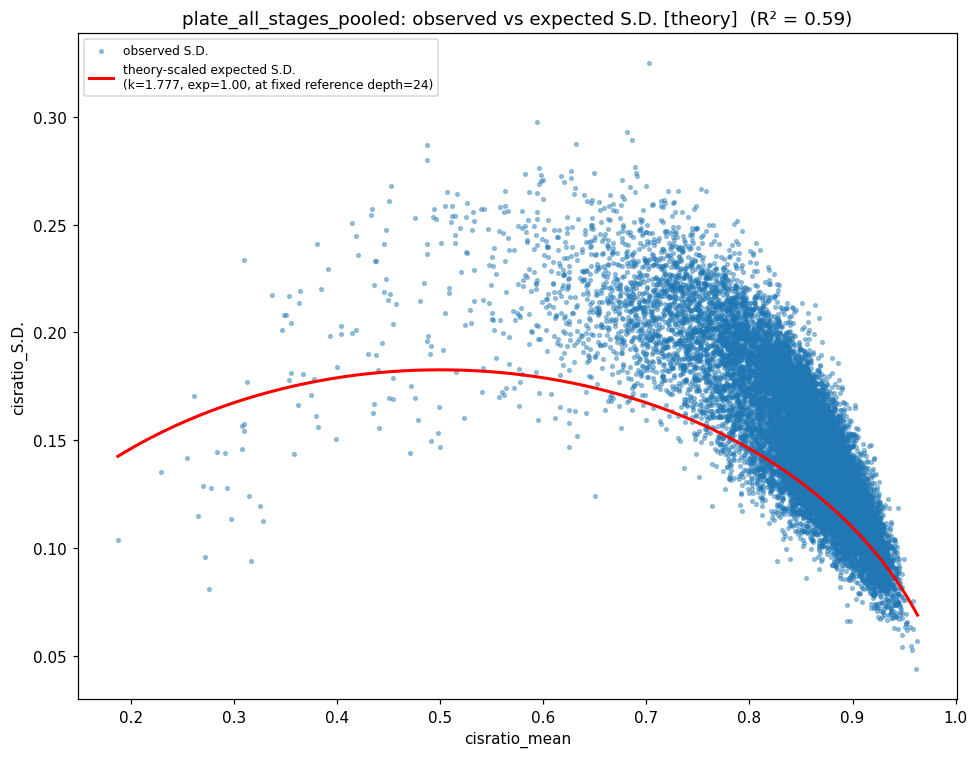

  [plate_all_stages_pooled] method=theory, R²=0.595
  wrote: normalized_output/plate_pooled_diagnostic_plot.pdf


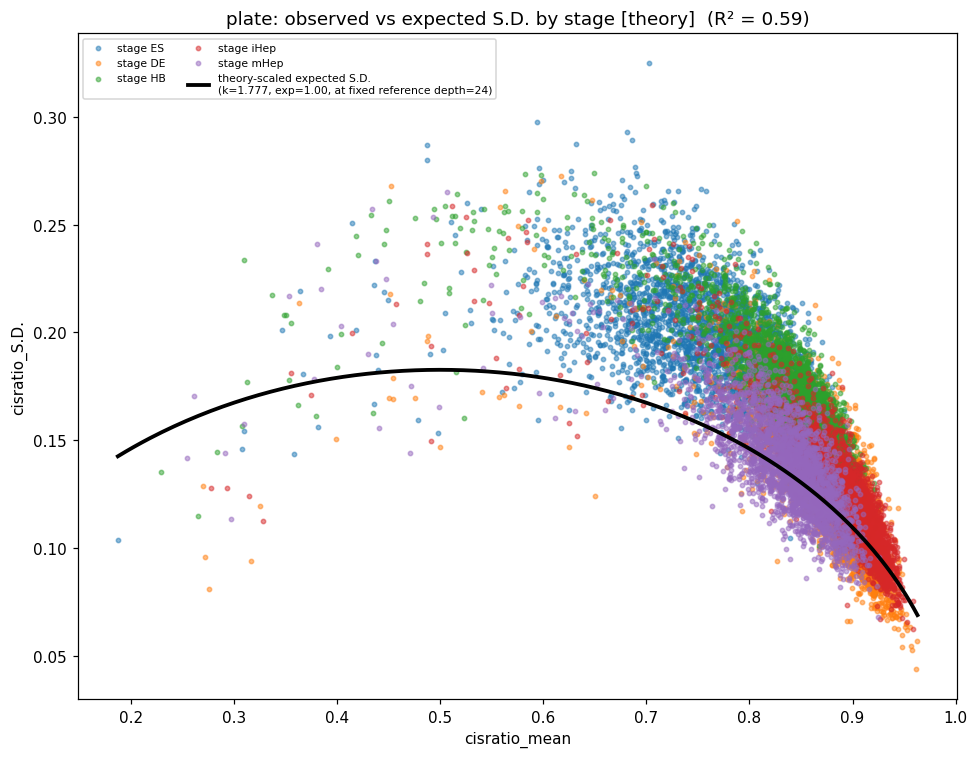

  wrote: normalized_output/plate_pooled_by_stage_diagnostic_plot.pdf


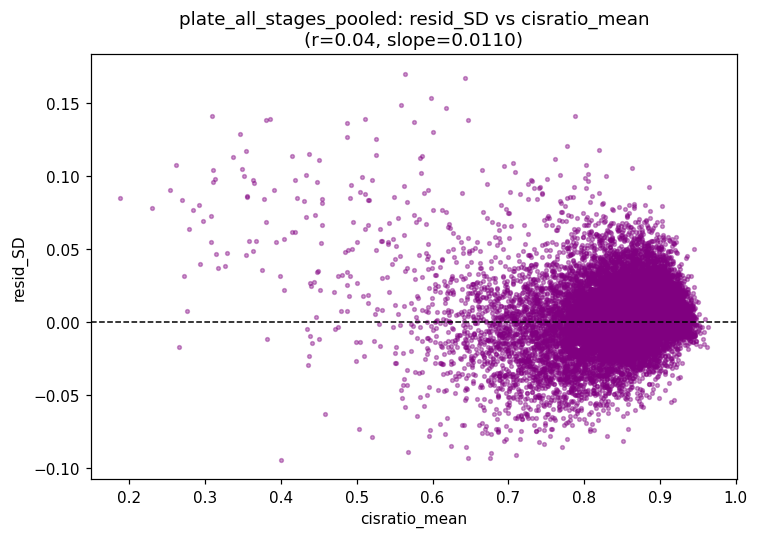

  [plate_all_stages_pooled] resid_SD vs mean: r=0.035, slope=0.01098


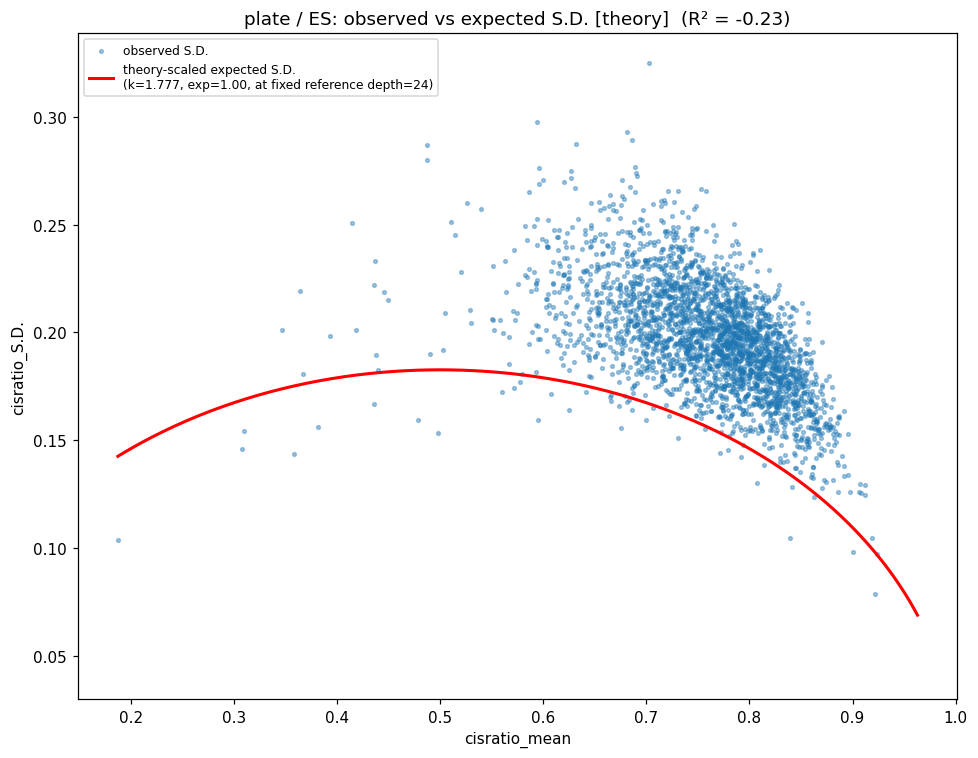

  [plate / ES] method=theory, R²=-0.231
  wrote: normalized_output/plate_ES_diagnostic_plot.pdf


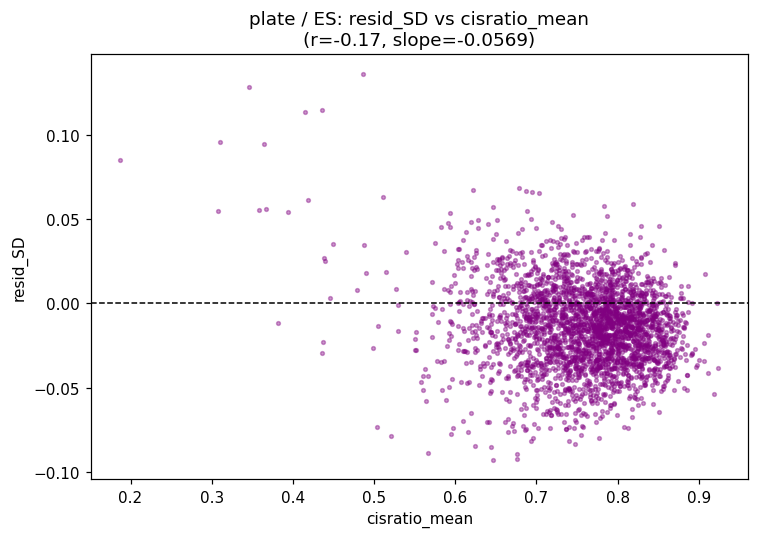

  [plate / ES] resid_SD vs mean: r=-0.172, slope=-0.05686


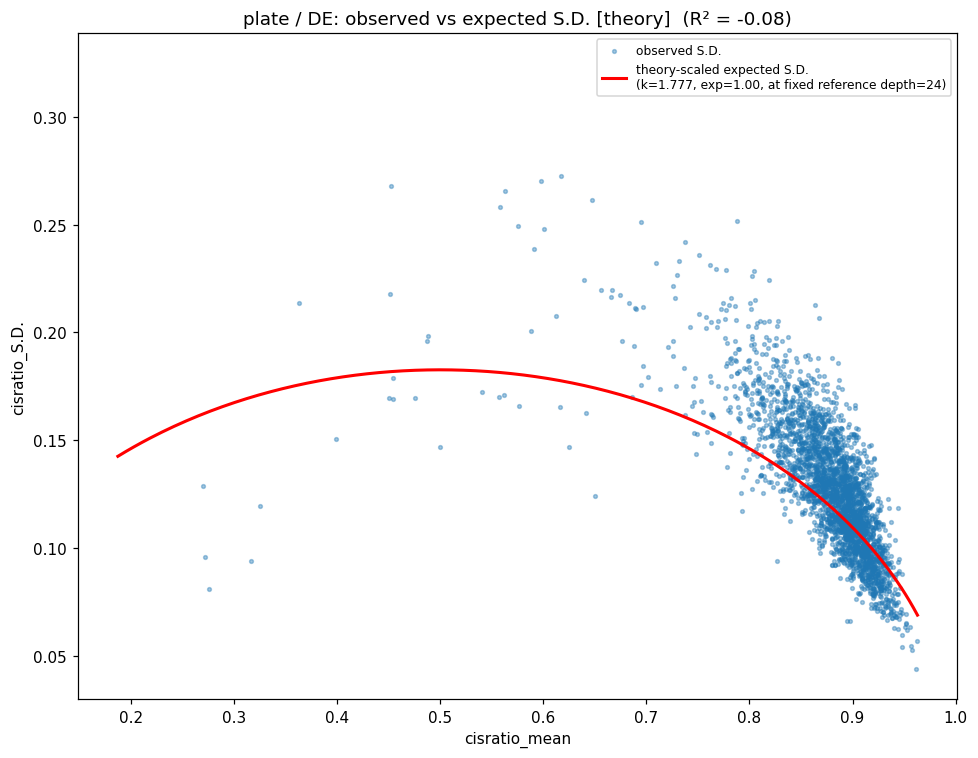

  [plate / DE] method=theory, R²=-0.081
  wrote: normalized_output/plate_DE_diagnostic_plot.pdf


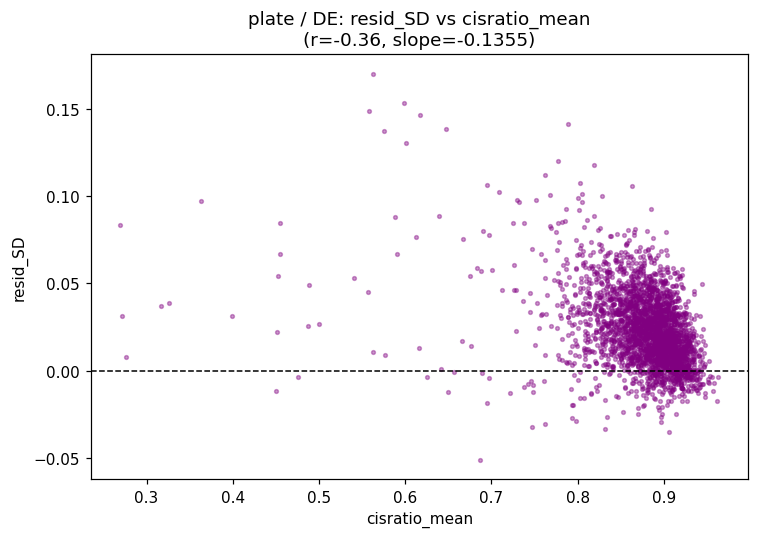

  [plate / DE] resid_SD vs mean: r=-0.364, slope=-0.13554


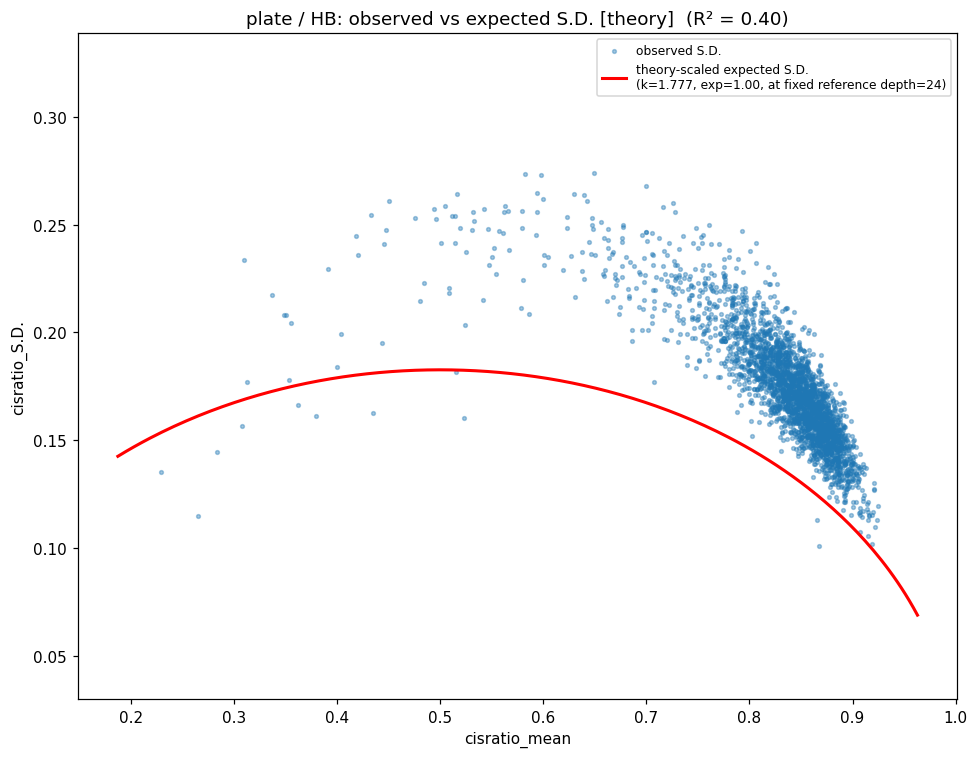

  [plate / HB] method=theory, R²=0.401
  wrote: normalized_output/plate_HB_diagnostic_plot.pdf


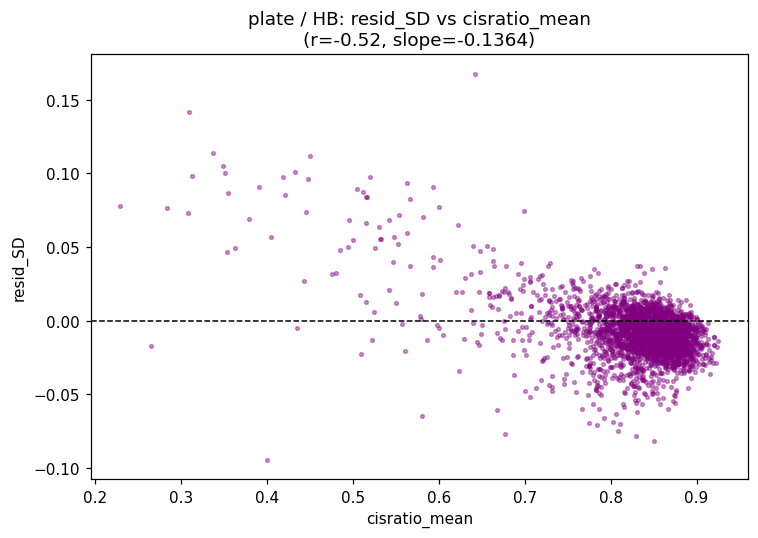

  [plate / HB] resid_SD vs mean: r=-0.518, slope=-0.13636


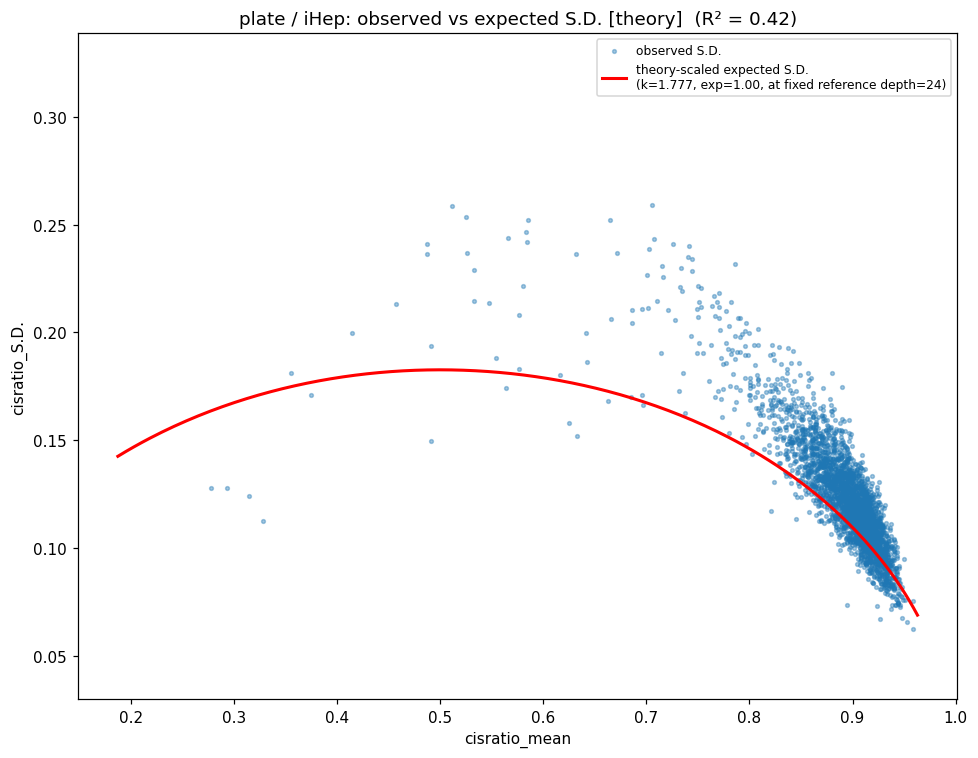

  [plate / iHep] method=theory, R²=0.417
  wrote: normalized_output/plate_iHep_diagnostic_plot.pdf


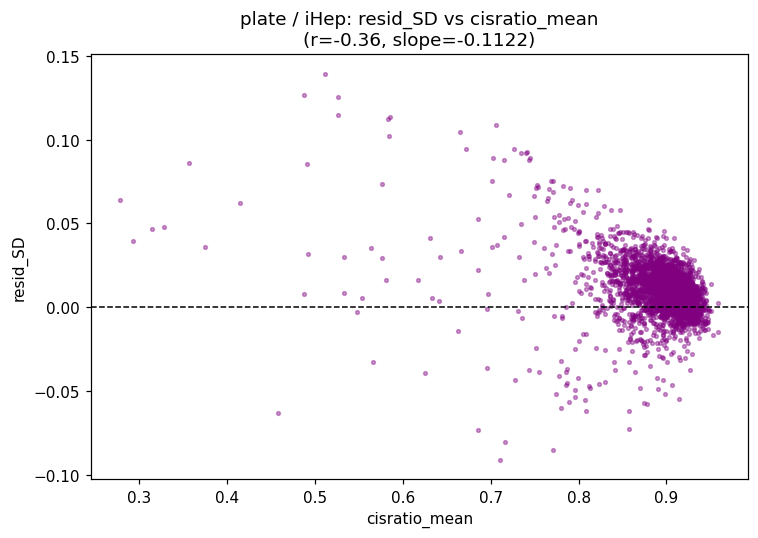

  [plate / iHep] resid_SD vs mean: r=-0.356, slope=-0.11223


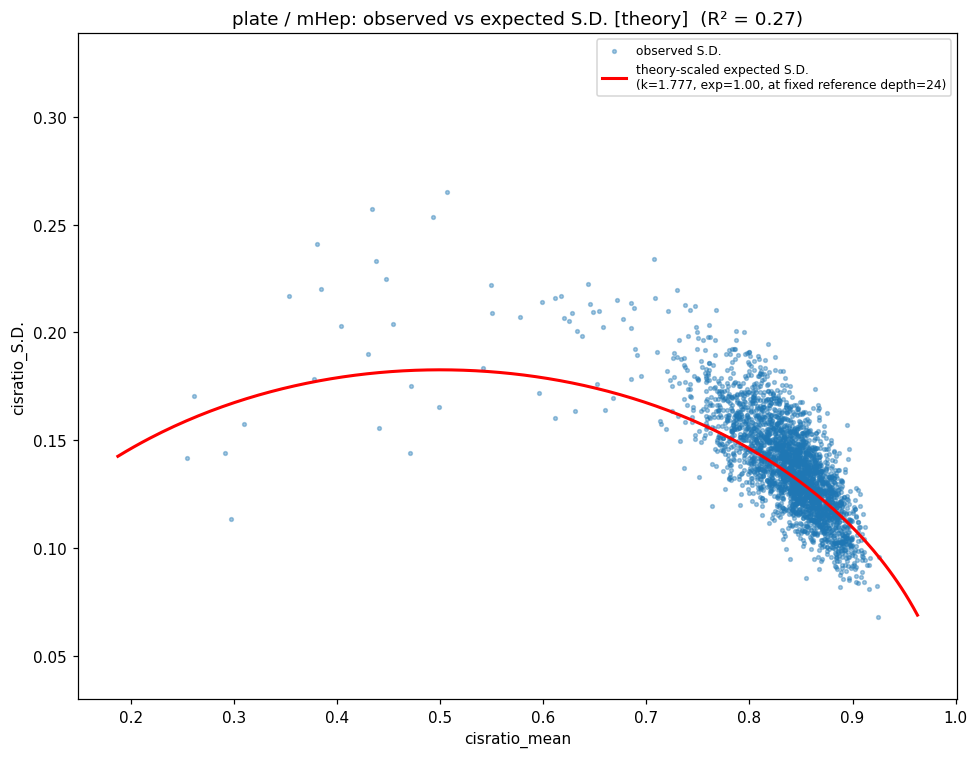

  [plate / mHep] method=theory, R²=0.266
  wrote: normalized_output/plate_mHep_diagnostic_plot.pdf


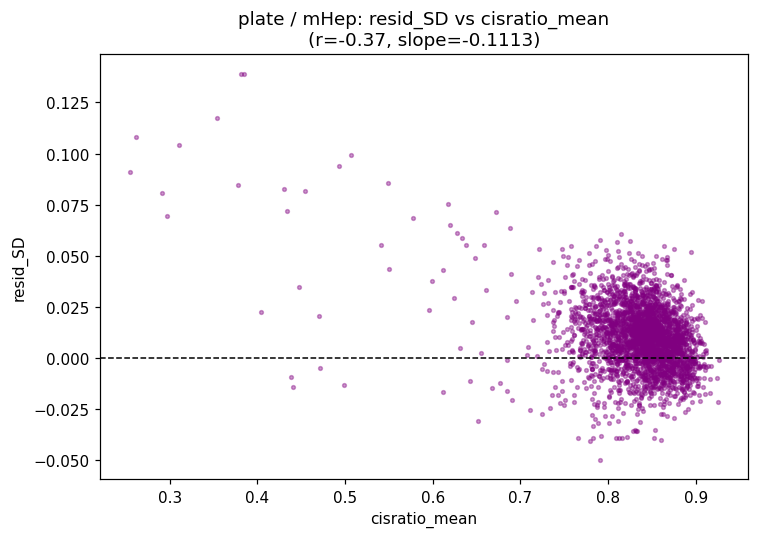

  [plate / mHep] resid_SD vs mean: r=-0.370, slope=-0.11132

[droplet] using method='lowess' (pooled across 5 stages, n=14330)
  (reference) theory-scaled overlay: k=1.2340, R² vs actual fit=-1.564


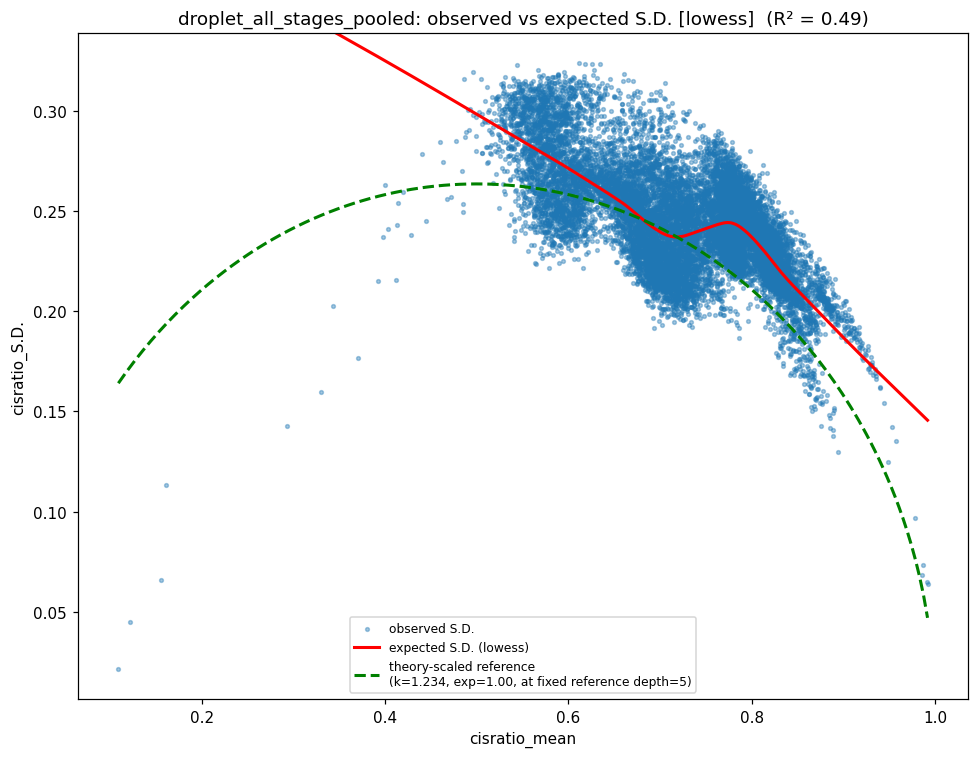

  [droplet_all_stages_pooled] method=lowess, R²=0.492
  wrote: normalized_output/droplet_pooled_diagnostic_plot.pdf


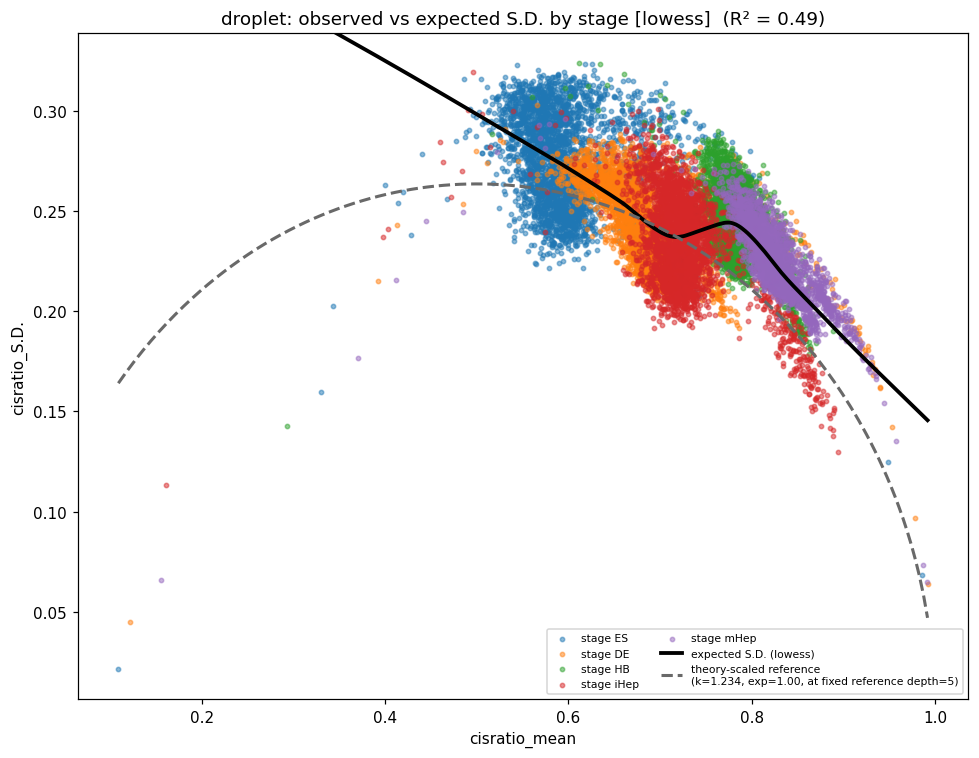

  wrote: normalized_output/droplet_pooled_by_stage_diagnostic_plot.pdf


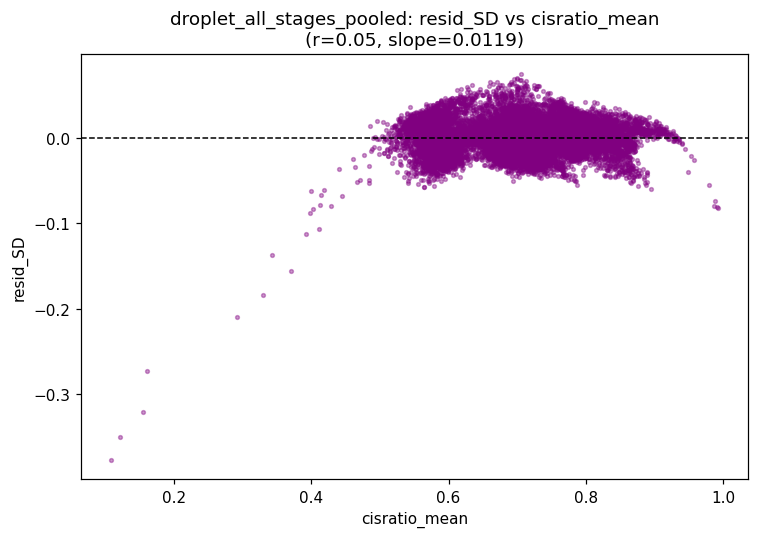

  [droplet_all_stages_pooled] resid_SD vs mean: r=0.055, slope=0.01195


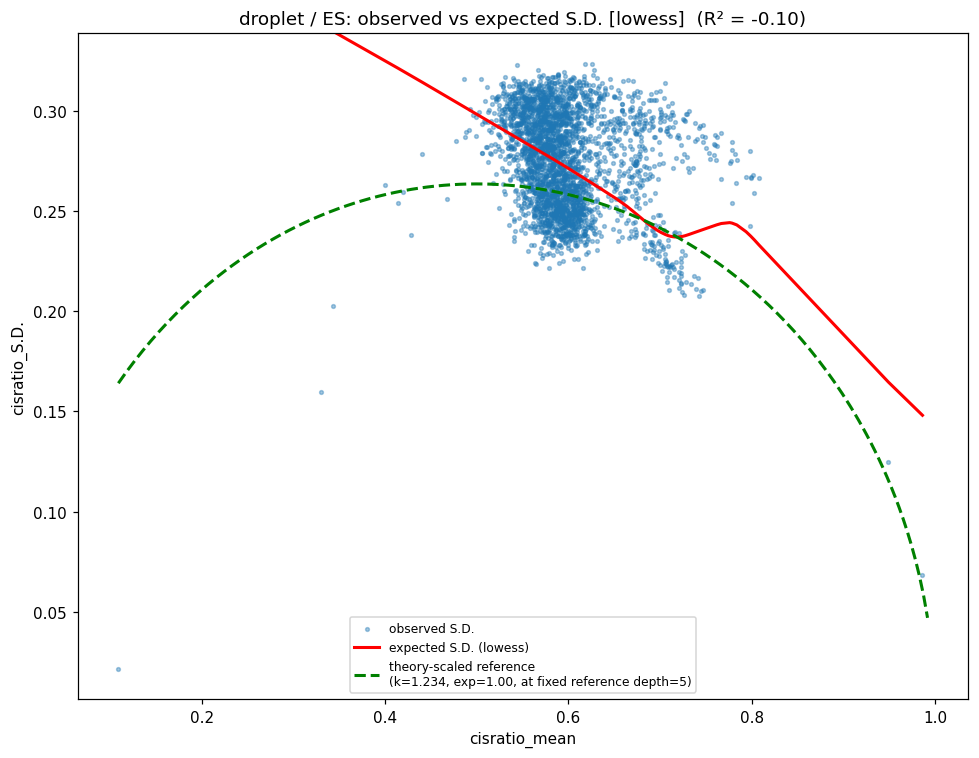

  [droplet / ES] method=lowess, R²=-0.104
  wrote: normalized_output/droplet_ES_diagnostic_plot.pdf


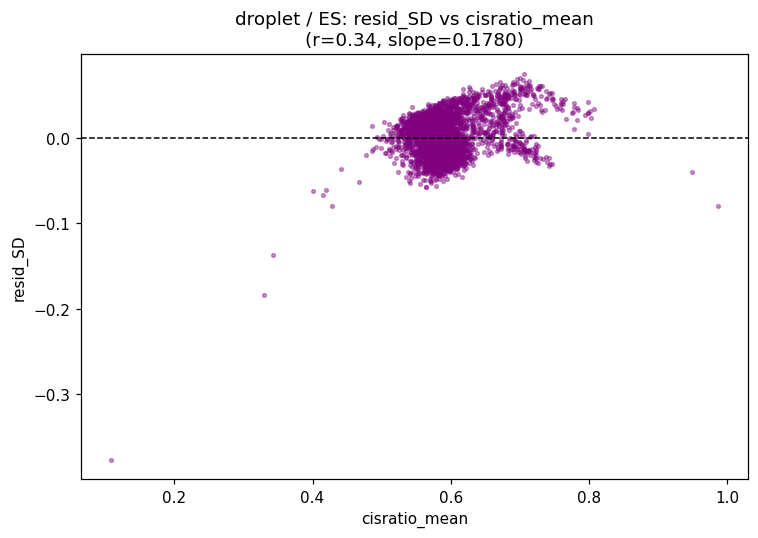

  [droplet / ES] resid_SD vs mean: r=0.344, slope=0.17799


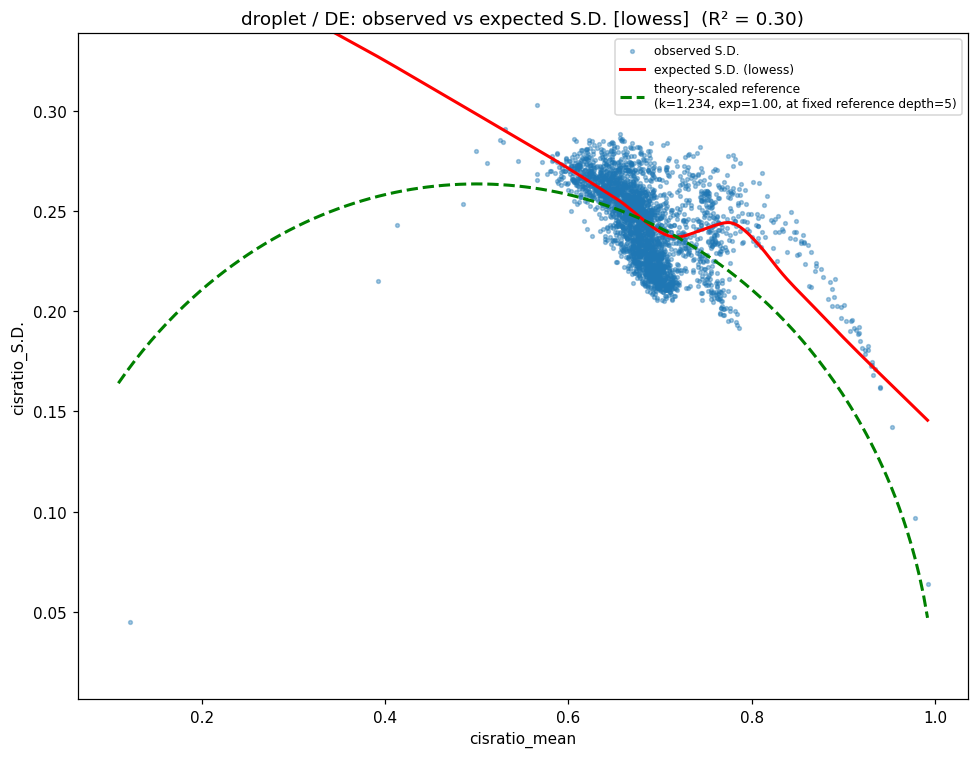

  [droplet / DE] method=lowess, R²=0.303
  wrote: normalized_output/droplet_DE_diagnostic_plot.pdf


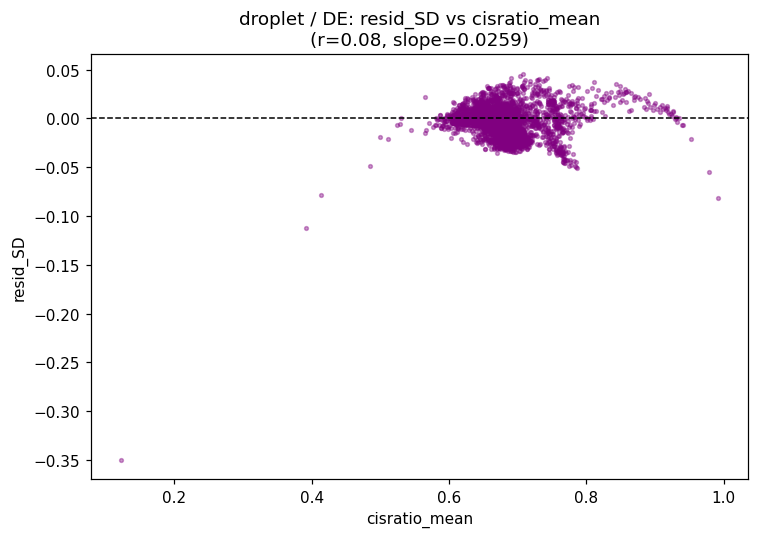

  [droplet / DE] resid_SD vs mean: r=0.080, slope=0.02592


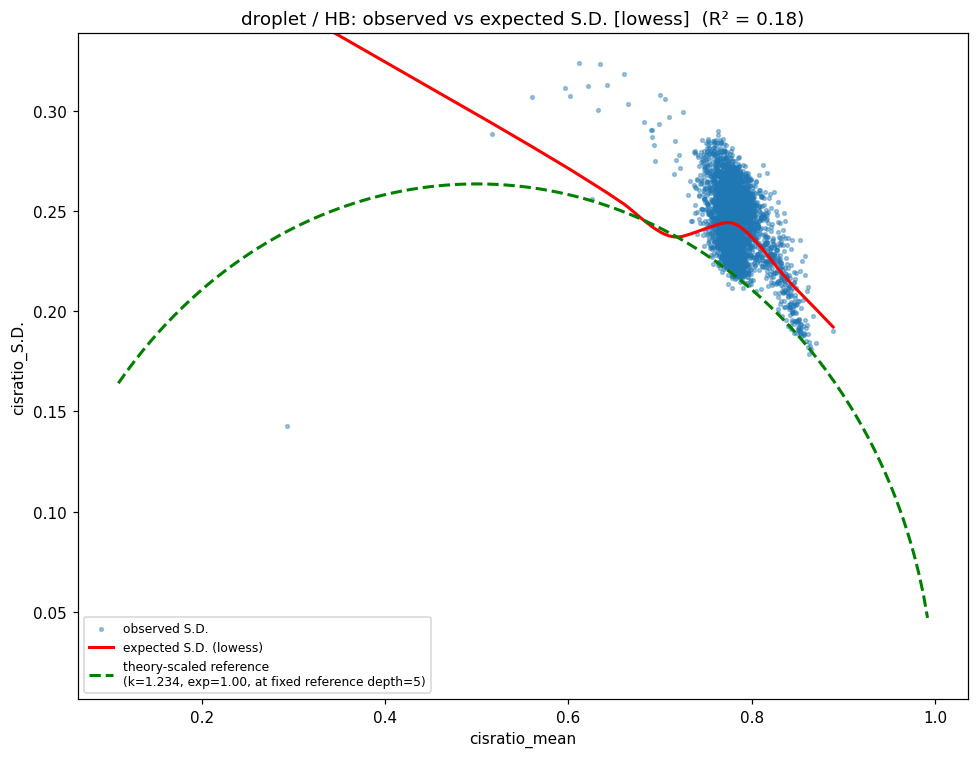

  [droplet / HB] method=lowess, R²=0.179
  wrote: normalized_output/droplet_HB_diagnostic_plot.pdf


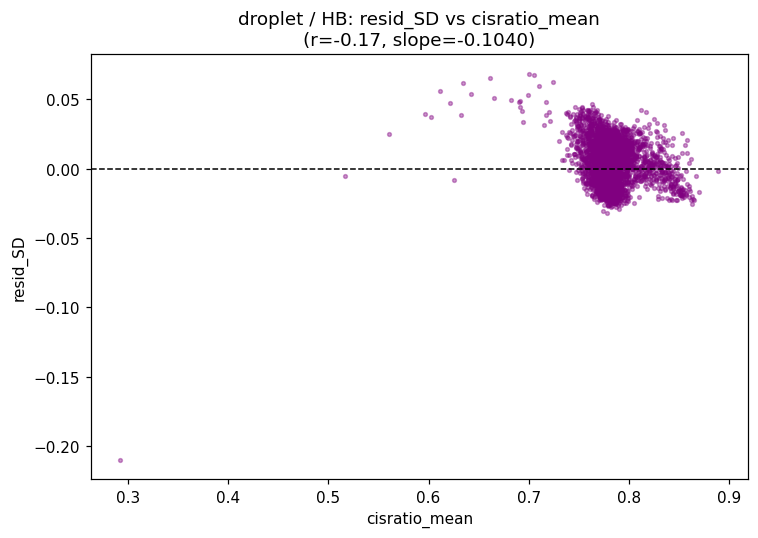

  [droplet / HB] resid_SD vs mean: r=-0.169, slope=-0.10398


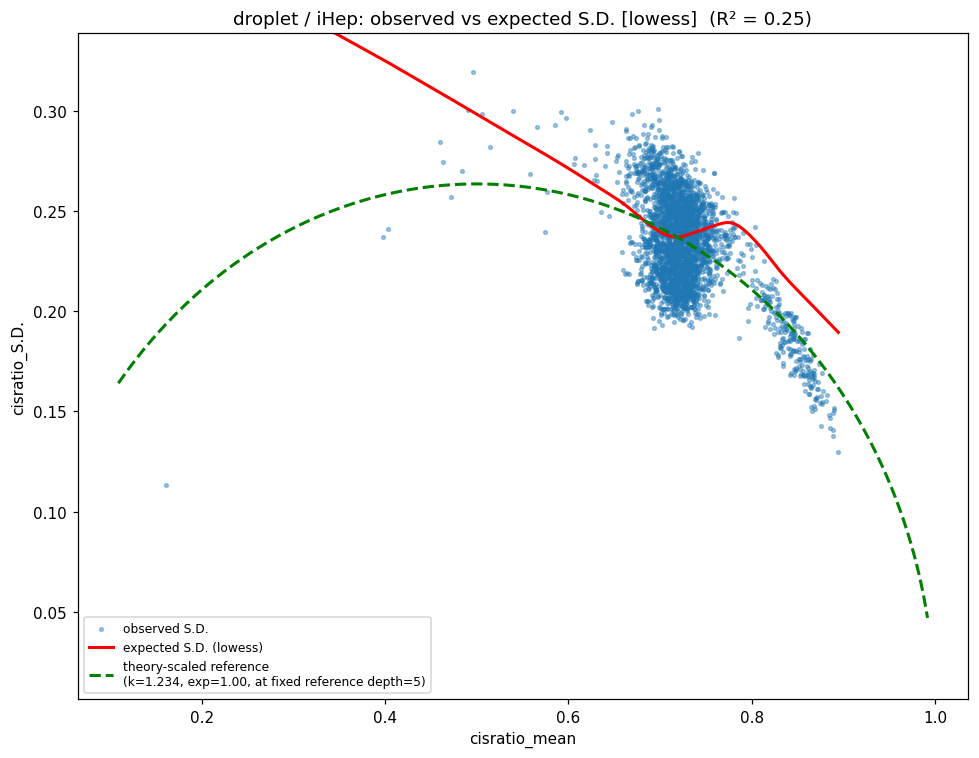

  [droplet / iHep] method=lowess, R²=0.253
  wrote: normalized_output/droplet_iHep_diagnostic_plot.pdf


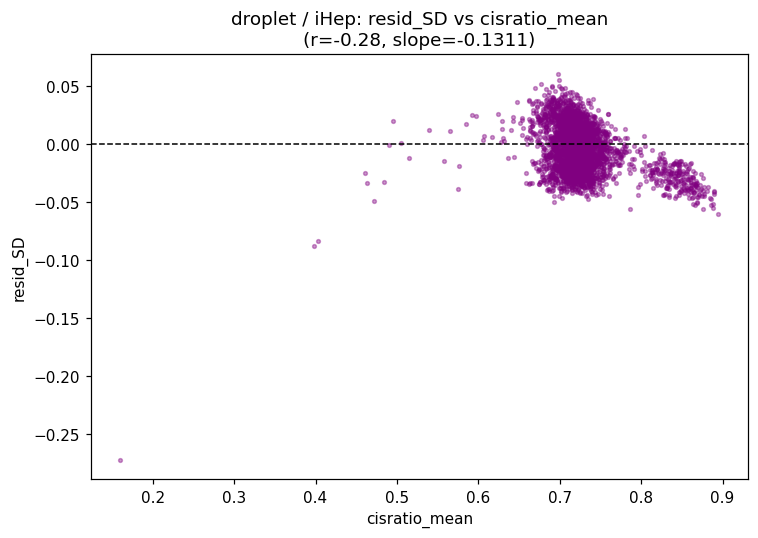

  [droplet / iHep] resid_SD vs mean: r=-0.279, slope=-0.13108


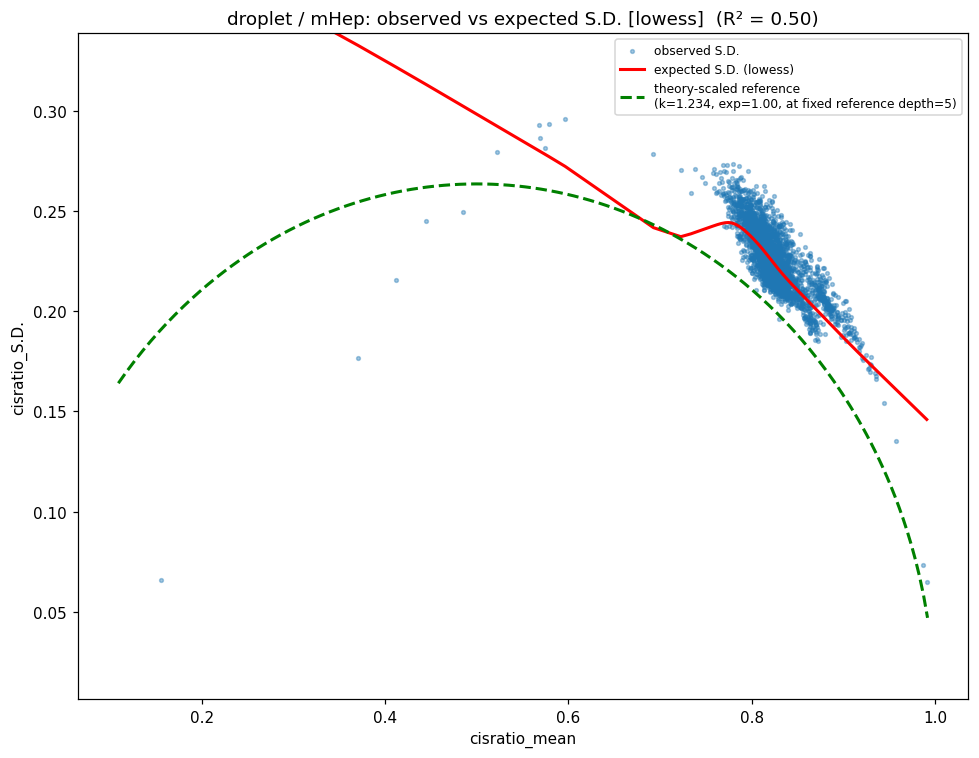

  [droplet / mHep] method=lowess, R²=0.499
  wrote: normalized_output/droplet_mHep_diagnostic_plot.pdf


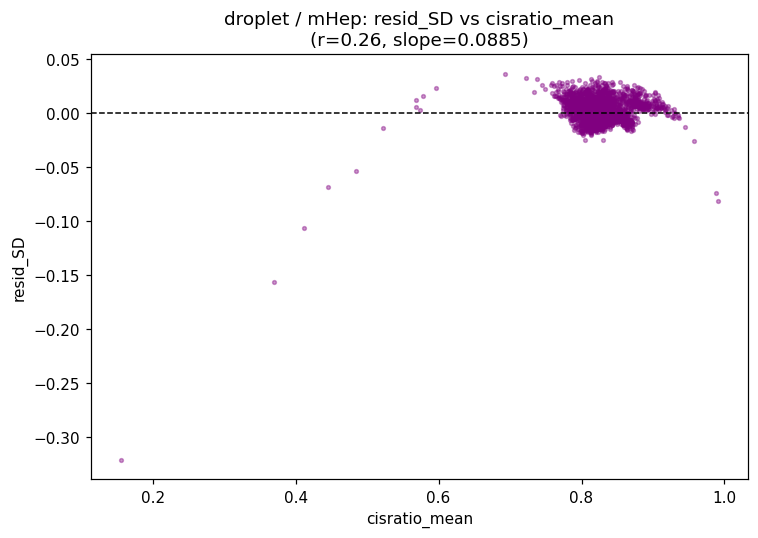

  [droplet / mHep] resid_SD vs mean: r=0.260, slope=0.08846

Method used per workflow: {'plate': 'theory', 'droplet': 'lowess'}
R² achieved per workflow: {'plate': 0.595, 'droplet': 0.492}
REMINDER: resid_SD / resid_SD_z are on DIFFERENT bases between plate and droplet (different fitting methods) -- compare stages WITHIN a workflow, not raw magnitudes ACROSS workflows.


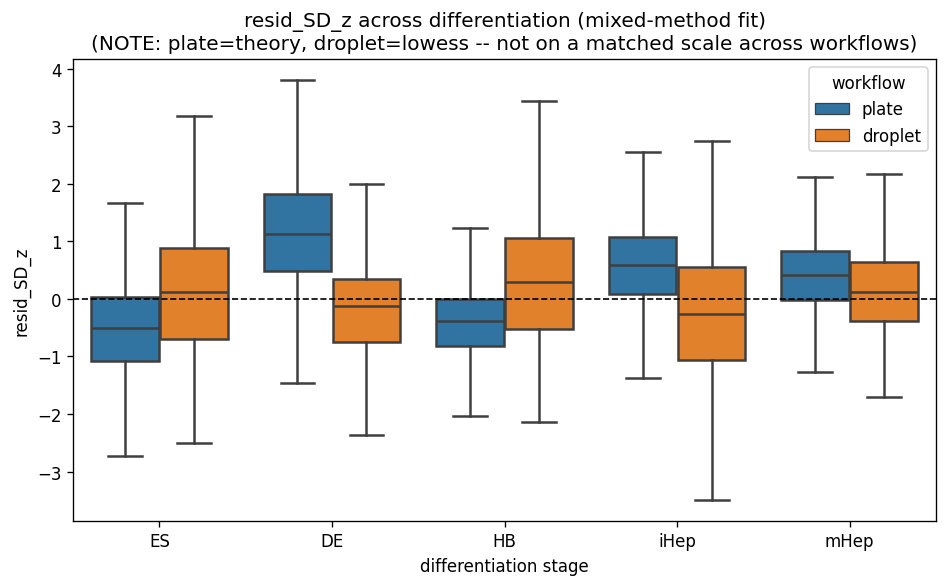

wrote: normalized_output/resid_SD_z_across_stages_mixed.pdf


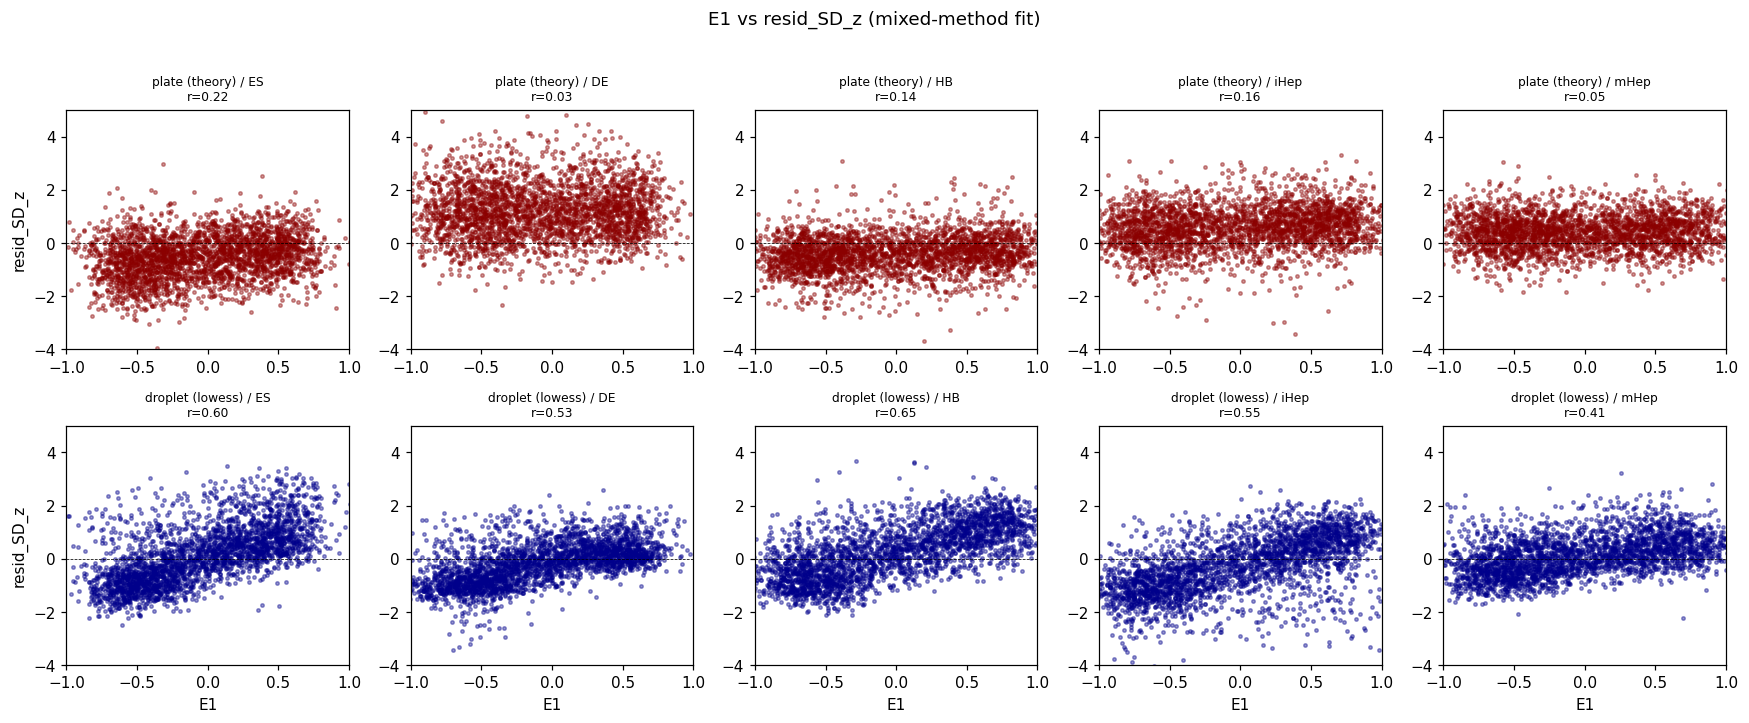

In [ ]:
"""
normalize_sd_mixed_methods.py
===============================

Uses a DIFFERENT fitting method per workflow, matched to each platform's own
signal-to-noise characteristics:

    plate   -> theory-scaled binomial model   (noisy, low signal-to-noise:
                                                a simple, constrained model is
                                                harder to overfit than LOWESS
                                                on this data)
    droplet -> LOWESS                         (clean, high signal-to-noise:
                                                the data supports a flexible
                                                empirical fit; LOWESS already
                                                achieves a high R^2 here)

IMPORTANT CAVEAT: because the two workflows are normalized with different
methods, do NOT directly compare resid_SD / resid_SD_z MAGNITUDES between
plate and droplet -- the two residual definitions aren't on a matched scale
(they remove different amounts/shapes of variance by construction). This
script is designed for the comparison you actually want: STAGE-TO-STAGE
trends WITHIN each workflow (holding the platform and its fitting method
fixed across all 5 stages).

pip install pandas numpy statsmodels matplotlib seaborn scipy --break-system-packages
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ---------------- config ------------------------------------------------------

STAGES = ["ES", "DE", "HB", "iHep", "mHep"]
contact_dist = 300

PLATE_STAGE_TOKEN = {stage: stage for stage in STAGES}
DROPLET_STAGE_TOKEN = {stage: stage for stage in STAGES}
DROPLET_STAGE_TOKEN["ES"] = "H1"  # known filename mismatch

PLATE_PATHS = {
    stage: f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/'
           f'comp_bin_cisratio_{PLATE_STAGE_TOKEN[stage]}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'
    for stage in STAGES
}
DROPLET_PATHS = {
    stage: f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/'
           f'dropletHiC_{DROPLET_STAGE_TOKEN[stage]}_comp_bin_cisratio_filter<0.4kb.txt'
    for stage in STAGES
}

COL_MEAN = "cisratio_mean"
COL_SD   = "cisratio_S.D."
COL_N    = "total_counts_Mean"
COL_SUM  = "total_counts_sum"

MIN_TOTAL_COUNTS = {"plate": 500, "droplet": 500}

# ---- the key config for this script: method per workflow ----
METHOD_BY_WORKFLOW = {
    "plate": "theory",     # noisy / low signal-to-noise -> constrained theory-scaled model
    "droplet": "lowess",   # clean / high signal-to-noise -> flexible empirical LOWESS
}

FIX_EXPONENT_AT_ONE = True   # for the theory method, when used
LOWESS_FRAC = 0.4             # for the lowess method, when used
LOWESS_ROBUST_ITERS = 3
MIN_ROWS_FOR_LOWESS = 30
N_MEAN_BINS_FOR_LOCAL_SPREAD = 20

OUTDIR = Path("normalized_output")
OUTDIR.mkdir(exist_ok=True)

# ---------------- fitting methods ---------------------------------------------


def fit_theory_scaled(mean_vals, sd_vals, n_vals, fix_exponent_at_one=FIX_EXPONENT_AT_ONE):
    p = np.clip(mean_vals, 1e-6, 1 - 1e-6)
    n = np.where(n_vals > 0, n_vals, np.nan)
    theory = np.sqrt(p * (1 - p) / n)
    valid = (~np.isnan(theory)) & (~np.isnan(sd_vals)) & (theory > 0) & (sd_vals > 0)

    if fix_exponent_at_one:
        k = np.sum(sd_vals[valid] * theory[valid]) / np.sum(theory[valid] ** 2)
        exponent = 1.0
    else:
        x = np.log(theory[valid]); y = np.log(sd_vals[valid])
        exponent, log_k = np.polyfit(x, y, deg=1)
        k = np.exp(log_k)

    def predict_fn(mean_arr, n_arr):
        m = np.clip(np.asarray(mean_arr, dtype=float), 1e-6, 1 - 1e-6)
        nn = np.where(np.asarray(n_arr, dtype=float) > 0, n_arr, np.nan)
        th = np.sqrt(m * (1 - m) / nn)
        return k * (th ** exponent)

    return predict_fn, {"method": "theory", "k": k, "exponent": exponent}


def fit_lowess(mean_vals, sd_vals, n_vals=None, frac=LOWESS_FRAC):
    """n_vals accepted (and ignored) so this has the SAME call signature as fit_theory_scaled,
    letting downstream code call either fitter uniformly."""
    n_valid = np.sum(~np.isnan(mean_vals) & ~np.isnan(sd_vals))

    if n_valid >= MIN_ROWS_FOR_LOWESS:
        from statsmodels.nonparametric.smoothers_lowess import lowess
        mask = ~np.isnan(mean_vals) & ~np.isnan(sd_vals)
        x, y = mean_vals[mask], sd_vals[mask]
        order = np.argsort(x)
        smoothed = lowess(y[order], x[order], frac=frac, it=LOWESS_ROBUST_ITERS, return_sorted=True)
        xs, ys = smoothed[:, 0], smoothed[:, 1]
        xs_u, idx = np.unique(xs, return_index=True)
        ys_u = ys[idx]

        def predict_fn(mean_arr, n_arr=None):
            m = np.asarray(mean_arr, dtype=float)
            out = np.full(m.shape, np.nan)
            valid = ~np.isnan(m)
            out[valid] = np.interp(m[valid], xs_u, ys_u, left=ys_u[0], right=ys_u[-1])
            return out

        return predict_fn, {"method": "lowess", "frac": frac}
    else:
        mask = ~np.isnan(mean_vals) & ~np.isnan(sd_vals)
        coeffs = np.polyfit(mean_vals[mask], sd_vals[mask], deg=2)

        def predict_fn(mean_arr, n_arr=None):
            return np.polyval(coeffs, np.asarray(mean_arr, dtype=float))

        return predict_fn, {"method": "quadratic_fallback"}


def fit_for_workflow(workflow, mean_vals, sd_vals, n_vals):
    method = METHOD_BY_WORKFLOW.get(workflow, "lowess")
    if method == "theory":
        return fit_theory_scaled(mean_vals, sd_vals, n_vals)
    else:
        return fit_lowess(mean_vals, sd_vals, n_vals)


def compute_r2(sd_vals, expected):
    valid = ~np.isnan(sd_vals) & ~np.isnan(expected)
    ss_res = np.nansum((sd_vals[valid] - expected[valid]) ** 2)
    ss_tot = np.nansum((sd_vals[valid] - np.nanmean(sd_vals[valid])) ** 2)
    return 1 - ss_res / ss_tot if ss_tot > 0 else np.nan


def local_residual_spread(mean_vals, resid_vals, n_bins=N_MEAN_BINS_FOR_LOCAL_SPREAD):
    mask = ~np.isnan(mean_vals) & ~np.isnan(resid_vals)
    x, r = mean_vals[mask], resid_vals[mask]
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 3:
        g = np.nanstd(r) if np.nanstd(r) > 0 else 1.0
        return lambda m: np.full(np.asarray(m).shape, g)

    bin_idx = np.digitize(x, edges[1:-1])
    centers, stds = [], []
    for b in range(len(edges) - 1):
        sel = bin_idx == b
        if sel.sum() >= 5:
            centers.append(x[sel].mean()); stds.append(r[sel].std(ddof=1))
    if len(centers) < 2:
        g = np.nanstd(r) if np.nanstd(r) > 0 else 1.0
        return lambda m: np.full(np.asarray(m).shape, g)

    centers, stds = np.array(centers), np.array(stds)
    order = np.argsort(centers); centers, stds = centers[order], stds[order]

    def predict_std(m):
        m = np.asarray(m, dtype=float)
        out = np.full(m.shape, np.nan)
        valid = ~np.isnan(m)
        out[valid] = np.interp(m[valid], centers, stds, left=stds[0], right=stds[-1])
        out[out <= 0] = np.nanmedian(stds[stds > 0]) if np.any(stds > 0) else 1.0
        return out

    return predict_std


def apply_normalization(df, predict_fn, local_std_fn):
    mean_vals = df[COL_MEAN].to_numpy(dtype=float)
    sd_vals = df[COL_SD].to_numpy(dtype=float)
    n_vals = df[COL_N].to_numpy(dtype=float) if COL_N in df.columns else np.full(len(df), np.nan)

    df = df.copy()
    df["expected_SD"] = predict_fn(mean_vals, n_vals)
    df["resid_SD"] = sd_vals - df["expected_SD"]
    df["resid_SD_local_std"] = local_std_fn(mean_vals)
    df["resid_SD_z"] = df["resid_SD"] / df["resid_SD_local_std"]
    return df


# ---------------- load -------------------------------------------------------

def load_all():
    data = {"plate": {}, "droplet": {}}
    for stage, path in PLATE_PATHS.items():
        if not Path(path).exists():
            print(f"[skip] plate {stage}: file not found at {path}")
            continue
        df = pd.read_csv(path, sep="\t", index_col=0).reset_index()
        df["stage"] = stage; df["workflow"] = "plate"
        df = df[df[COL_SUM] >= MIN_TOTAL_COUNTS["plate"]]
        data["plate"][stage] = df

    for stage, path in DROPLET_PATHS.items():
        if not Path(path).exists():
            print(f"[skip] droplet {stage}: file not found at {path}")
            continue
        df = pd.read_csv(path, sep="\t", index_col=0).reset_index()
        df["stage"] = stage; df["workflow"] = "droplet"
        df = df[df[COL_SUM] >= MIN_TOTAL_COUNTS["droplet"]]
        data["droplet"][stage] = df

    return data


# ---------------- diagnostics -------------------------------------------------

def compute_workflow_ylim(stage_dfs, pad_frac=0.05):
    all_sd = pd.concat([df[COL_SD] for df in stage_dfs.values()], ignore_index=True).to_numpy(dtype=float)
    valid = all_sd[~np.isnan(all_sd)]
    if valid.size == 0:
        return None
    lo, hi = np.nanmin(valid), np.nanmax(valid)
    pad = (hi - lo) * pad_frac
    return (lo - pad, hi + pad)


def plot_diagnostic(label, mean_vals, sd_vals, n_vals, predict_fn, fit_meta, out_name, ylim=None,
                     theory_overlay=None, reference_n=None, x_range=None):
    """cisratio_mean (x) vs cisratio_S.D. (y). Curve style adapts to which method was used.
    theory_overlay: optional (predict_theory_fn, theory_meta) to draw the theory-scaled curve
    as a secondary reference line, even when the PRIMARY fit for this workflow is LOWESS --
    useful for visually comparing the empirical trend against the calibrated binomial model.
    reference_n: depth value to use when drawing a theory-based curve, so the SAME curve is
    drawn across every stage of a workflow (rather than each stage's own median depth, which
    made the curve appear to shift stage-to-stage even though the fitted k/exponent don't
    change). Defaults to this call's own median(n_vals) if not given.
    x_range: (min, max) mean range to draw curves over, so all stages use the SAME x-span too
    (defaults to this call's own mean range if not given)."""
    order = np.argsort(mean_vals)
    expected = predict_fn(mean_vals, n_vals)
    r2 = compute_r2(sd_vals, expected)

    fig, ax = plt.subplots(figsize=(9, 7), dpi=110)
    ax.scatter(mean_vals, sd_vals, s=6, alpha=0.4, label="observed S.D.")

    curve_n = reference_n if reference_n is not None else np.nanmedian(n_vals)
    if x_range is not None:
        x_lo, x_hi = x_range
    else:
        x_lo, x_hi = np.nanmin(mean_vals), np.nanmax(mean_vals)

    if fit_meta["method"] == "theory":
        x_grid = np.linspace(x_lo, x_hi, 200)
        curve = predict_fn(x_grid, np.full_like(x_grid, curve_n))
        ax.plot(x_grid, curve, color="red", lw=2,
                label=f"theory-scaled expected S.D.\n(k={fit_meta['k']:.3f}, "
                      f"exp={fit_meta['exponent']:.2f}, at fixed reference depth={curve_n:.0f})")
    else:
        ax.plot(mean_vals[order], expected[order], color="red", lw=2,
                label=f"expected S.D. ({fit_meta['method']})")

    if theory_overlay is not None and fit_meta["method"] != "theory":
        predict_theory_fn, theory_meta = theory_overlay
        x_grid = np.linspace(x_lo, x_hi, 200)
        theory_curve = predict_theory_fn(x_grid, np.full_like(x_grid, curve_n))
        ax.plot(x_grid, theory_curve, color="green", lw=2, ls="--",
                label=f"theory-scaled reference\n(k={theory_meta['k']:.3f}, "
                      f"exp={theory_meta['exponent']:.2f}, at fixed reference depth={curve_n:.0f})")

    ax.set_xlabel("cisratio_mean"); ax.set_ylabel("cisratio_S.D.")
    ax.set_title(f"{label}: observed vs expected S.D. [{fit_meta['method']}]  (R\u00b2 = {r2:.2f})")
    ax.legend(fontsize=8)
    if ylim is not None:
        ax.set_ylim(*ylim)
    fig.tight_layout()

    out_path = OUTDIR / f"{out_name}_diagnostic_plot.pdf"
    fig.savefig(out_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"  [{label}] method={fit_meta['method']}, R\u00b2={r2:.3f}")
    print(f"  wrote: {out_path}")
    return r2


def plot_diagnostic_by_stage(workflow, stage_dfs, predict_fn, fit_meta, out_name, ylim=None,
                              theory_overlay=None, reference_n=None, x_range=None):
    """Same pooled diagnostic plot (cisratio_mean vs cisratio_S.D.), but with each stage's
    points colored separately, so you can see how the stages' scatter compares directly on
    one figure, against the SAME shared curve(s)."""
    pooled = pd.concat(stage_dfs.values(), ignore_index=True)
    mean_vals = pooled[COL_MEAN].to_numpy(dtype=float)
    sd_vals = pooled[COL_SD].to_numpy(dtype=float)
    n_vals = pooled[COL_N].to_numpy(dtype=float) if COL_N in pooled.columns else np.full(len(pooled), np.nan)

    expected = predict_fn(mean_vals, n_vals)
    r2 = compute_r2(sd_vals, expected)

    curve_n = reference_n if reference_n is not None else np.nanmedian(n_vals)
    if x_range is not None:
        x_lo, x_hi = x_range
    else:
        x_lo, x_hi = np.nanmin(mean_vals), np.nanmax(mean_vals)
    x_grid = np.linspace(x_lo, x_hi, 200)

    fig, ax = plt.subplots(figsize=(9, 7), dpi=110)

    palette = sns.color_palette("tab10", n_colors=len(STAGES))
    stage_colors = dict(zip(STAGES, palette))
    for stage in STAGES:
        if stage not in stage_dfs:
            continue
        df = stage_dfs[stage]
        ax.scatter(df[COL_MEAN], df[COL_SD], s=8, alpha=0.5,
                   color=stage_colors[stage], label=f"stage {stage}")

    if fit_meta["method"] == "theory":
        curve = predict_fn(x_grid, np.full_like(x_grid, curve_n))
        ax.plot(x_grid, curve, color="black", lw=2.5,
                label=f"theory-scaled expected S.D.\n(k={fit_meta['k']:.3f}, "
                      f"exp={fit_meta['exponent']:.2f}, at fixed reference depth={curve_n:.0f})")
    else:
        order = np.argsort(mean_vals)
        ax.plot(mean_vals[order], expected[order], color="black", lw=2.5,
                label=f"expected S.D. ({fit_meta['method']})")

    if theory_overlay is not None and fit_meta["method"] != "theory":
        predict_theory_fn, theory_meta = theory_overlay
        theory_curve = predict_theory_fn(x_grid, np.full_like(x_grid, curve_n))
        ax.plot(x_grid, theory_curve, color="dimgray", lw=2, ls="--",
                label=f"theory-scaled reference\n(k={theory_meta['k']:.3f}, "
                      f"exp={theory_meta['exponent']:.2f}, at fixed reference depth={curve_n:.0f})")

    ax.set_xlabel("cisratio_mean"); ax.set_ylabel("cisratio_S.D.")
    ax.set_title(f"{workflow}: observed vs expected S.D. by stage [{fit_meta['method']}]  "
                 f"(R\u00b2 = {r2:.2f})")
    ax.legend(fontsize=7, ncol=2)
    if ylim is not None:
        ax.set_ylim(*ylim)
    fig.tight_layout()

    out_path = OUTDIR / f"{out_name}_by_stage_diagnostic_plot.pdf"
    fig.savefig(out_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"  wrote: {out_path}")


def plot_residual_vs_mean(label, mean_vals, resid_vals, out_name, ylim=None):
    fig, ax = plt.subplots(figsize=(7, 5), dpi=110)
    ax.scatter(mean_vals, resid_vals, s=6, alpha=0.4, color="purple")
    ax.axhline(0, color="black", lw=1, ls="--")

    valid = ~np.isnan(mean_vals) & ~np.isnan(resid_vals)
    if valid.sum() >= 2:
        from scipy.stats import pearsonr
        r, _ = pearsonr(mean_vals[valid], resid_vals[valid])
        slope = np.polyfit(mean_vals[valid], resid_vals[valid], deg=1)[0]
    else:
        r, slope = np.nan, np.nan

    ax.set_xlabel("cisratio_mean"); ax.set_ylabel("resid_SD")
    ax.set_title(f"{label}: resid_SD vs cisratio_mean\n(r={r:.2f}, slope={slope:.4f})")
    if ylim is not None:
        ax.set_ylim(*ylim)
    fig.tight_layout()

    out_path = OUTDIR / f"{out_name}_resid_vs_mean.pdf"
    fig.savefig(out_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"  [{label}] resid_SD vs mean: r={r:.3f}, slope={slope:.5f}")
    return r, slope


# ---------------- fit per workflow (mixed methods) -----------------------------

def fit_and_normalize_mixed(data):
    normalized = {"plate": {}, "droplet": {}}
    r2_info = {}

    for workflow in ["plate", "droplet"]:
        stage_dfs = data[workflow]
        if not stage_dfs:
            continue
        pooled = pd.concat(stage_dfs.values(), ignore_index=True)

        mean_vals = pooled[COL_MEAN].to_numpy(dtype=float)
        sd_vals = pooled[COL_SD].to_numpy(dtype=float)
        n_vals = pooled[COL_N].to_numpy(dtype=float) if COL_N in pooled.columns else np.full(len(pooled), np.nan)

        predict_fn, fit_meta = fit_for_workflow(workflow, mean_vals, sd_vals, n_vals)
        print(f"\n[{workflow}] using method='{fit_meta['method']}' "
              f"(pooled across {len(stage_dfs)} stages, n={len(pooled)})")

        # ALWAYS also fit the theory-scaled model (even if it isn't the primary method for this
        # workflow), purely so it can be overlaid as a reference curve on the diagnostic plots.
        predict_theory_fn, theory_meta = fit_theory_scaled(mean_vals, sd_vals, n_vals)
        theory_overlay = (predict_theory_fn, theory_meta)
        if fit_meta["method"] != "theory":
            theory_r2 = compute_r2(sd_vals, predict_theory_fn(mean_vals, n_vals))
            print(f"  (reference) theory-scaled overlay: k={theory_meta['k']:.4f}, "
                  f"R\u00b2 vs actual fit={theory_r2:.3f}")

        expected = predict_fn(mean_vals, n_vals)
        resid = sd_vals - expected
        local_std_fn = local_residual_spread(mean_vals, resid)

        # SHARED reference depth and x-range (from pooled data) so the drawn theory curve is
        # IDENTICAL across every stage's plot for this workflow -- only the scatter changes.
        workflow_reference_n = np.nanmedian(n_vals)
        workflow_x_range = (np.nanmin(mean_vals), np.nanmax(mean_vals))

        workflow_ylim = compute_workflow_ylim(stage_dfs)
        r2_info[workflow] = plot_diagnostic(
            f"{workflow}_all_stages_pooled", mean_vals, sd_vals, n_vals, predict_fn, fit_meta,
            out_name=f"{workflow}_pooled", ylim=workflow_ylim, theory_overlay=theory_overlay,
            reference_n=workflow_reference_n, x_range=workflow_x_range
        )
        plot_diagnostic_by_stage(
            workflow, stage_dfs, predict_fn, fit_meta, out_name=f"{workflow}_pooled",
            ylim=workflow_ylim, theory_overlay=theory_overlay,
            reference_n=workflow_reference_n, x_range=workflow_x_range
        )
        plot_residual_vs_mean(f"{workflow}_all_stages_pooled", mean_vals, resid, out_name=f"{workflow}_pooled")

        for stage, df in stage_dfs.items():
            stage_mean = df[COL_MEAN].to_numpy(dtype=float)
            stage_sd = df[COL_SD].to_numpy(dtype=float)
            stage_n = df[COL_N].to_numpy(dtype=float) if COL_N in df.columns else np.full(len(df), np.nan)
            plot_diagnostic(
                f"{workflow} / {stage}", stage_mean, stage_sd, stage_n, predict_fn, fit_meta,
                out_name=f"{workflow}_{stage}", ylim=workflow_ylim, theory_overlay=theory_overlay,
                reference_n=workflow_reference_n, x_range=workflow_x_range
            )
            stage_resid = stage_sd - predict_fn(stage_mean, stage_n)
            plot_residual_vs_mean(f"{workflow} / {stage}", stage_mean, stage_resid, out_name=f"{workflow}_{stage}")

        for stage, df in stage_dfs.items():
            normalized[workflow][stage] = apply_normalization(df, predict_fn, local_std_fn)

    print("\nMethod used per workflow:", METHOD_BY_WORKFLOW)
    print("R\u00b2 achieved per workflow:", {k: round(v, 3) for k, v in r2_info.items()})
    print("REMINDER: resid_SD / resid_SD_z are on DIFFERENT bases between plate and droplet "
          "(different fitting methods) -- compare stages WITHIN a workflow, not raw magnitudes "
          "ACROSS workflows.")

    return normalized, r2_info


# ---------------- assemble + plot trend across stages --------------------------

def assemble_long(normalized):
    frames = []
    for workflow in ["plate", "droplet"]:
        for stage, df in normalized[workflow].items():
            frames.append(df)
    return pd.concat(frames, ignore_index=True)


def plot_stage_trend(long_df, value_col="resid_SD_z", title_suffix="(mixed-method fit)"):
    fig, ax = plt.subplots(figsize=(8, 5), dpi=120)
    sns.boxplot(data=long_df, x="stage", y=value_col, hue="workflow", order=STAGES,
                showfliers=False, ax=ax)
    ax.axhline(0, color="black", lw=1, ls="--")
    ax.set_title(f"{value_col} across differentiation {title_suffix}\n"
                 f"(NOTE: plate={METHOD_BY_WORKFLOW['plate']}, droplet={METHOD_BY_WORKFLOW['droplet']} "
                 f"-- not on a matched scale across workflows)")
    ax.set_xlabel("differentiation stage"); ax.set_ylabel(value_col)
    fig.tight_layout()
    out_path = OUTDIR / f"{value_col}_across_stages_mixed.pdf"
    fig.savefig(out_path)
    plt.show()
    plt.close(fig)
    print(f"wrote: {out_path}")


def plot_e1_vs_resid(long_df, e1_col="E1", value_col="resid_SD_z", title_suffix="(mixed-method fit)"):
    from scipy.stats import pearsonr

    workflows = [wf for wf in ["plate", "droplet"] if wf in long_df["workflow"].unique()]
    stages_present = [s for s in STAGES if s in long_df["stage"].unique()]

    fig, axes = plt.subplots(len(workflows), len(stages_present),
                              figsize=(3.2 * len(stages_present), 3.2 * len(workflows)),
                              dpi=110, squeeze=False)

    for i, workflow in enumerate(workflows):
        for j, stage in enumerate(stages_present):
            ax = axes[i][j]
            sub = long_df[(long_df["workflow"] == workflow) & (long_df["stage"] == stage)]
            x = sub[e1_col]; y = sub[value_col]
            mask = (~x.isna()) & (~y.isna()) & np.isfinite(x) & np.isfinite(y)
            r = pearsonr(x[mask], y[mask])[0] if mask.sum() >= 2 else np.nan

            ax.scatter(x, y, s=5, alpha=0.4, color="darkblue" if workflow == "droplet" else "darkred")
            ax.axhline(0, color="black", lw=0.5, ls="--")
            ax.set_xlim(-1, 1)
            ax.set_ylim(-4, 5)
            ax.set_title(f"{workflow} ({METHOD_BY_WORKFLOW[workflow]}) / {stage}\nr={r:.2f}", fontsize=8)
            if i == len(workflows) - 1:
                ax.set_xlabel(e1_col)
            if j == 0:
                ax.set_ylabel(value_col)

    fig.suptitle(f"{e1_col} vs {value_col} {title_suffix}", y=1.02)
    fig.tight_layout()
    out_path = OUTDIR / f"{e1_col}_vs_{value_col}_mixed.pdf"
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"wrote: {out_path}")


# ---------------- run --------------------------------------------------------

if __name__ == "__main__":
    data = load_all()

    normalized, r2_info = fit_and_normalize_mixed(data)
    long_df = assemble_long(normalized)
    long_df.to_csv(OUTDIR / "all_stages_all_workflows_normalized_MIXED.txt", sep="\t", index=False)

    plot_stage_trend(long_df, "resid_SD_z")
    if "E1" in long_df.columns:
        plot_e1_vs_resid(long_df, "E1", "resid_SD_z")

    print("\nDone. Table: all_stages_all_workflows_normalized_MIXED.txt")
    print(f"plate normalized via: {METHOD_BY_WORKFLOW['plate']}")
    print(f"droplet normalized via: {METHOD_BY_WORKFLOW['droplet']}")

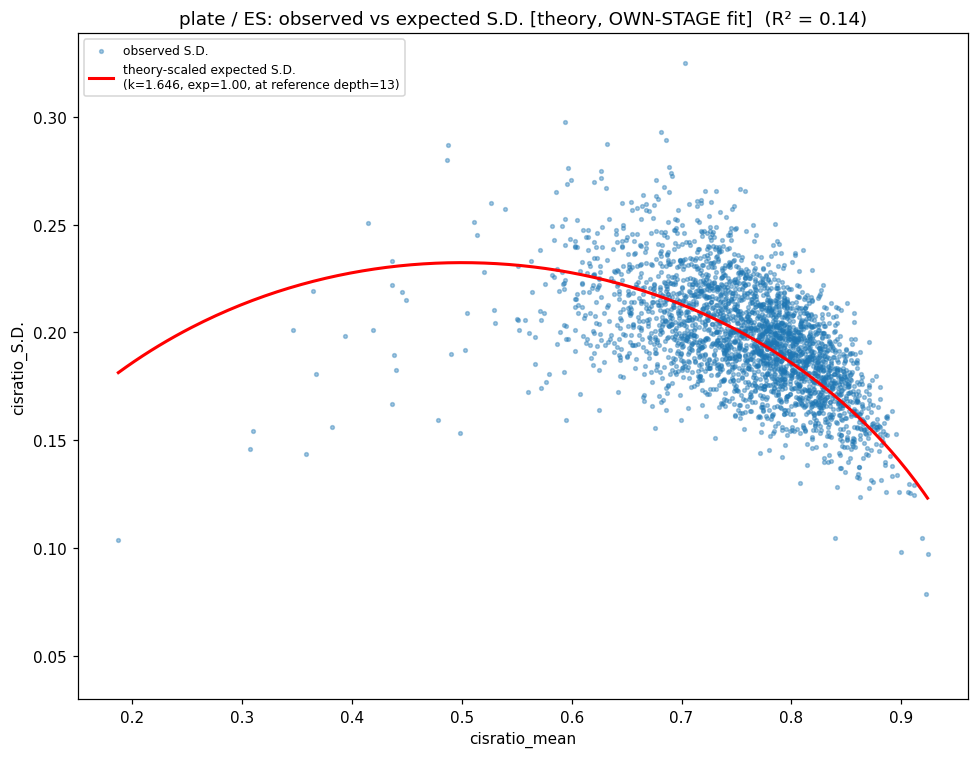

  [plate / ES] method=theory, R²=0.141
    k=1.6462, exponent=1.000
  wrote: normalized_output/plate_ES_ownfit_diagnostic_plot.pdf


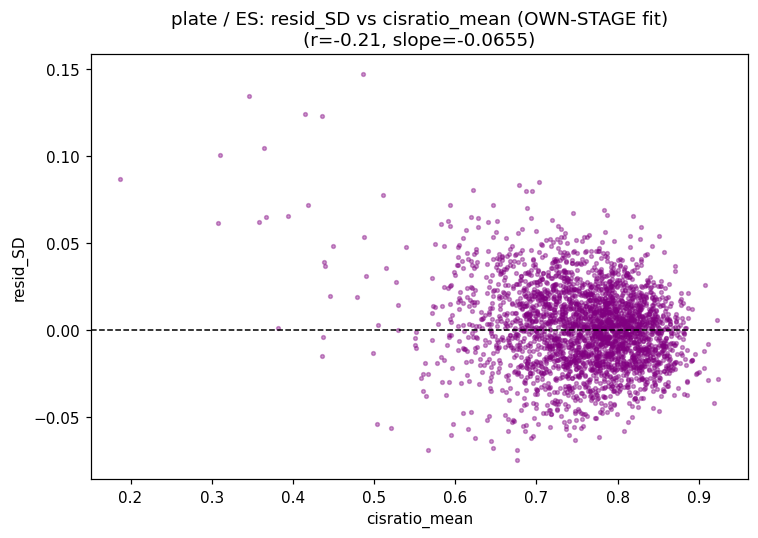

  [plate / ES] resid_SD vs mean: r=-0.205, slope=-0.06552


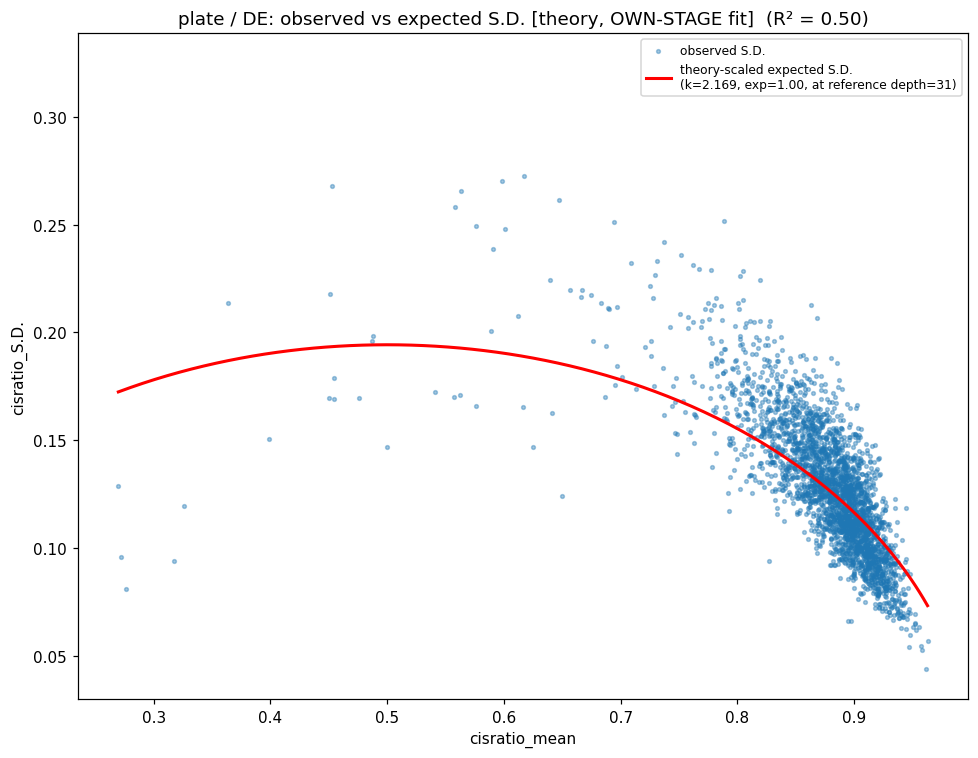

  [plate / DE] method=theory, R²=0.500
    k=2.1693, exponent=1.000
  wrote: normalized_output/plate_DE_ownfit_diagnostic_plot.pdf


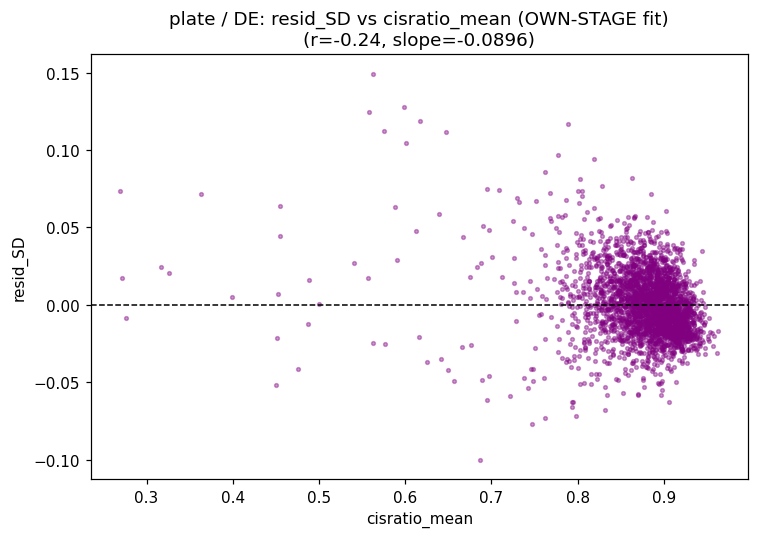

  [plate / DE] resid_SD vs mean: r=-0.241, slope=-0.08961


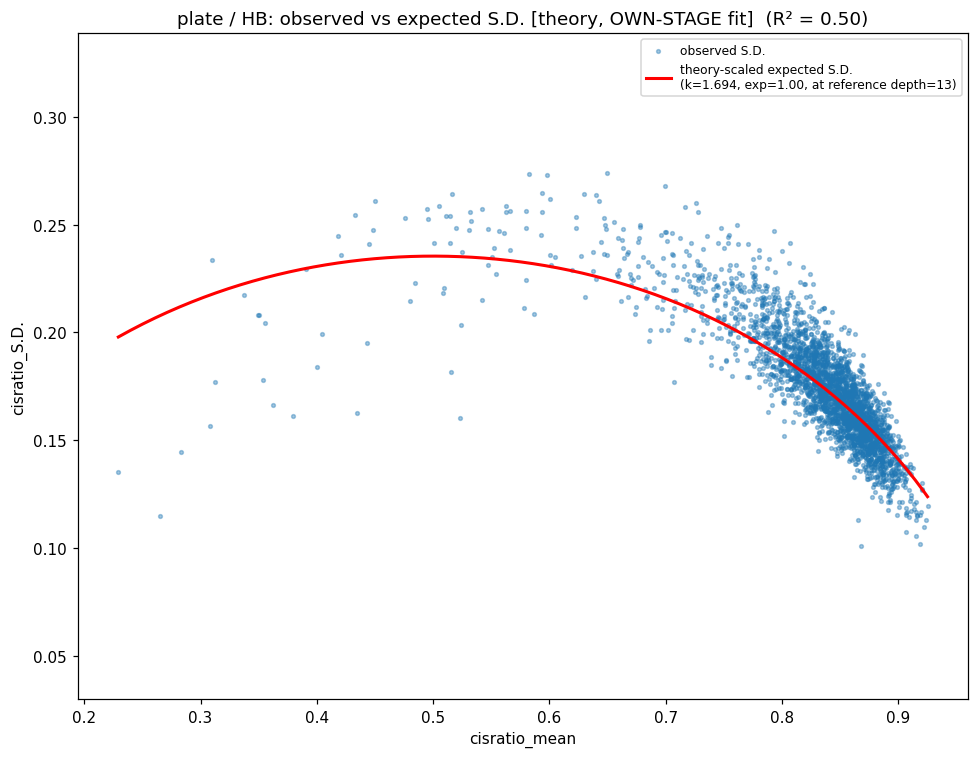

  [plate / HB] method=theory, R²=0.503
    k=1.6939, exponent=1.000
  wrote: normalized_output/plate_HB_ownfit_diagnostic_plot.pdf


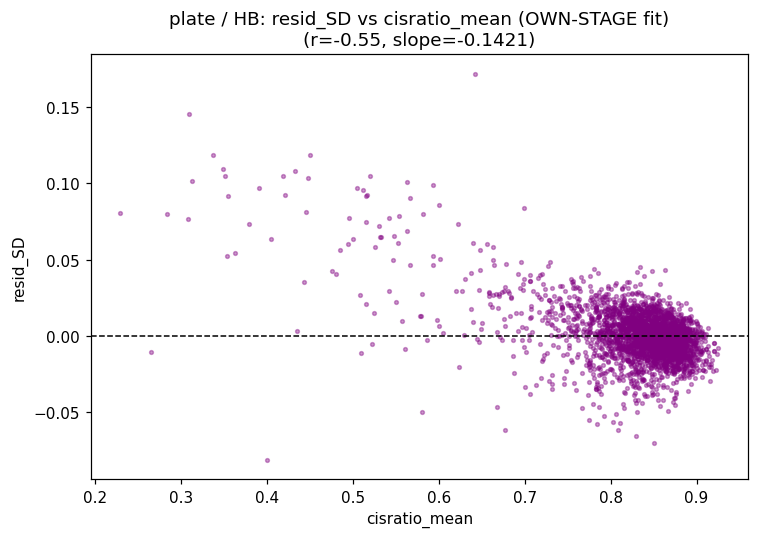

  [plate / HB] resid_SD vs mean: r=-0.549, slope=-0.14207


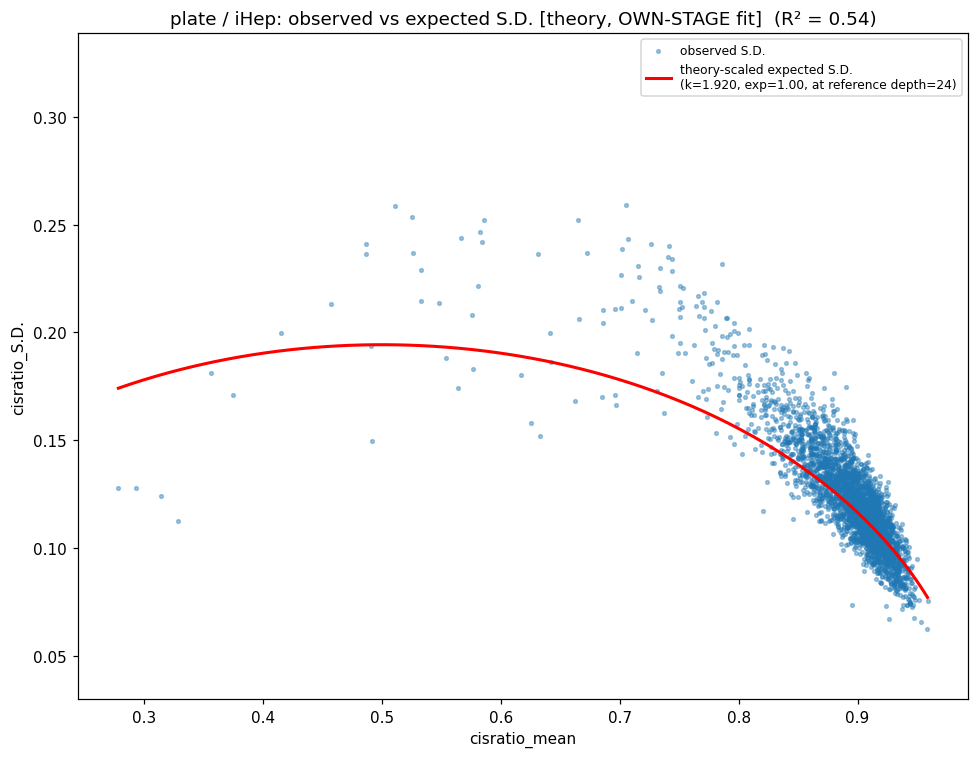

  [plate / iHep] method=theory, R²=0.538
    k=1.9203, exponent=1.000
  wrote: normalized_output/plate_iHep_ownfit_diagnostic_plot.pdf


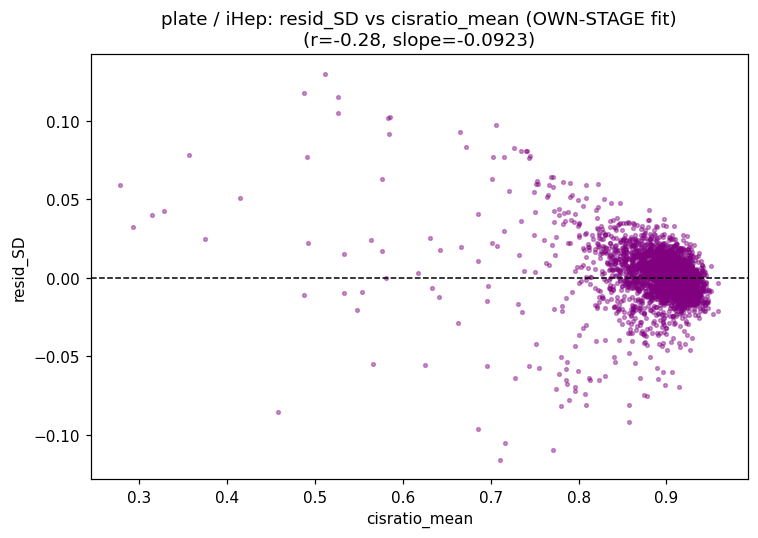

  [plate / iHep] resid_SD vs mean: r=-0.284, slope=-0.09226


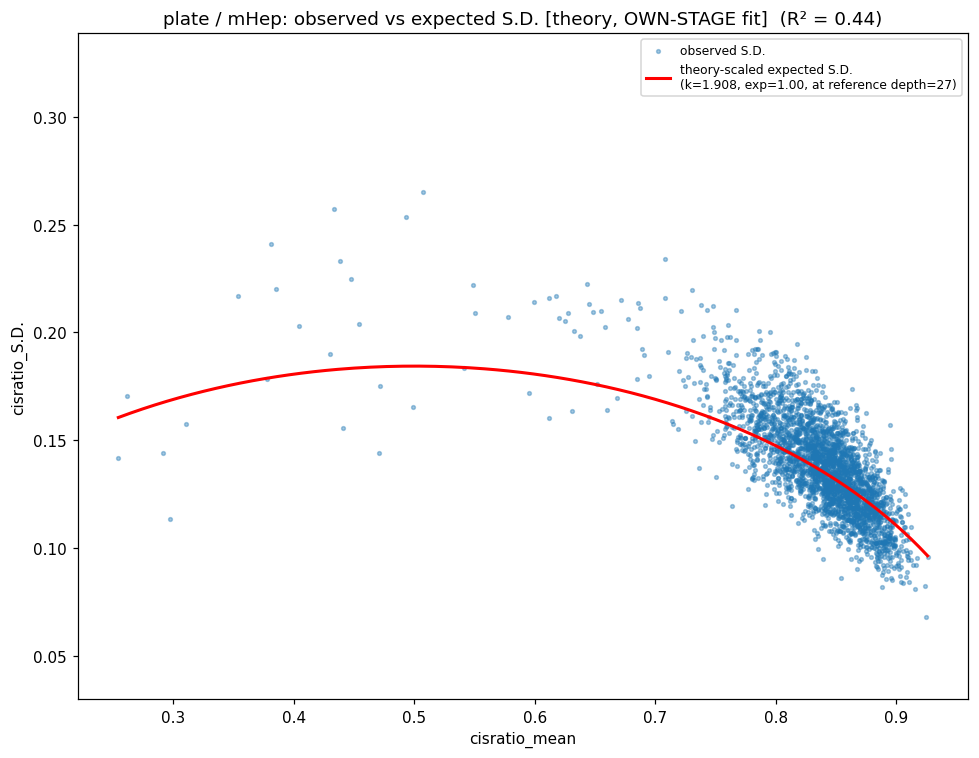

  [plate / mHep] method=theory, R²=0.438
    k=1.9083, exponent=1.000
  wrote: normalized_output/plate_mHep_ownfit_diagnostic_plot.pdf


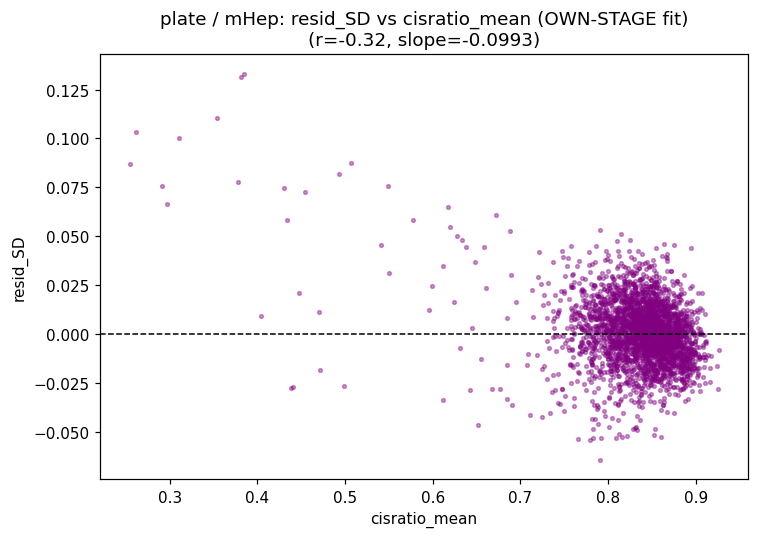

  [plate / mHep] resid_SD vs mean: r=-0.324, slope=-0.09934


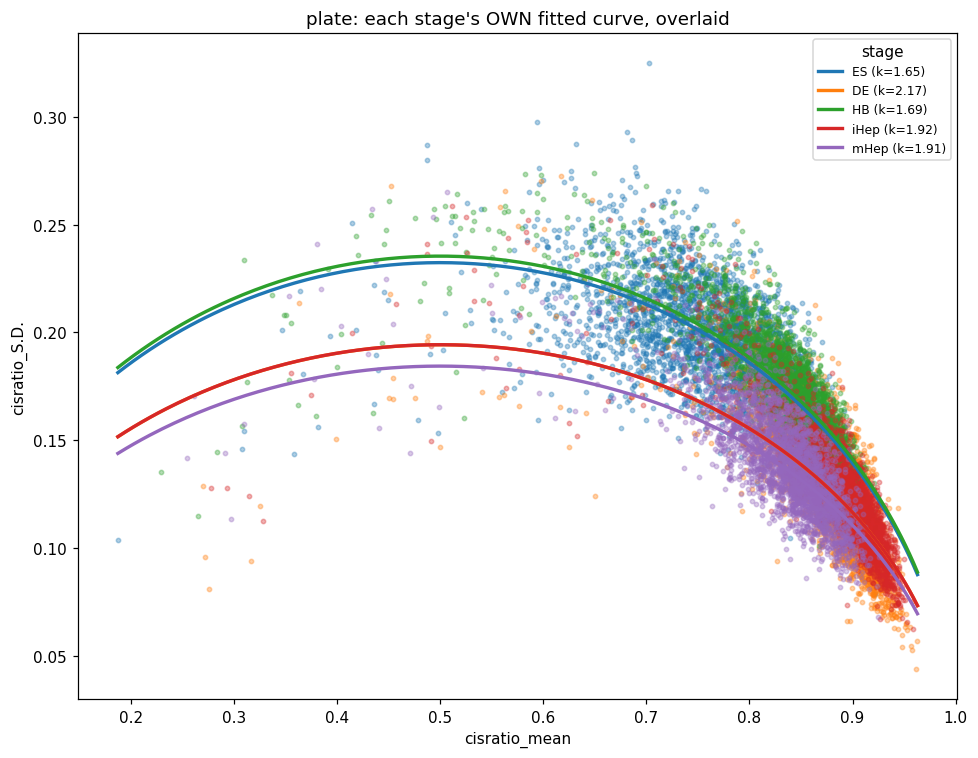

wrote: normalized_output/plate_own_fits_overlay.pdf

[plate] R² by stage: {'ES': 0.141, 'DE': 0.5, 'HB': 0.503, 'iHep': 0.538, 'mHep': 0.438}
[plate] overdispersion k by stage: {'ES': 1.6462, 'DE': 2.1693, 'HB': 1.6939, 'iHep': 1.9203, 'mHep': 1.9083}
  -> if k changes meaningfully across stages, that's evidence excess variability (beyond binomial sampling) itself shifts during differentiation, not just the mean cisratio distribution.


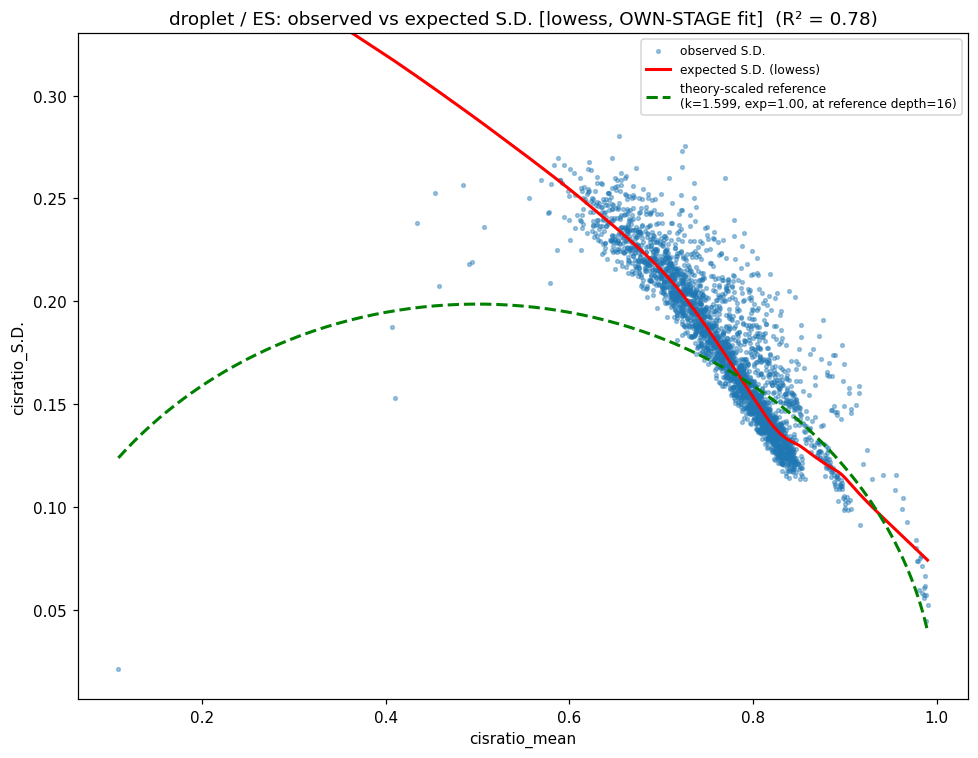

  [droplet / ES] method=lowess, R²=0.781
  wrote: normalized_output/droplet_ES_ownfit_diagnostic_plot.pdf


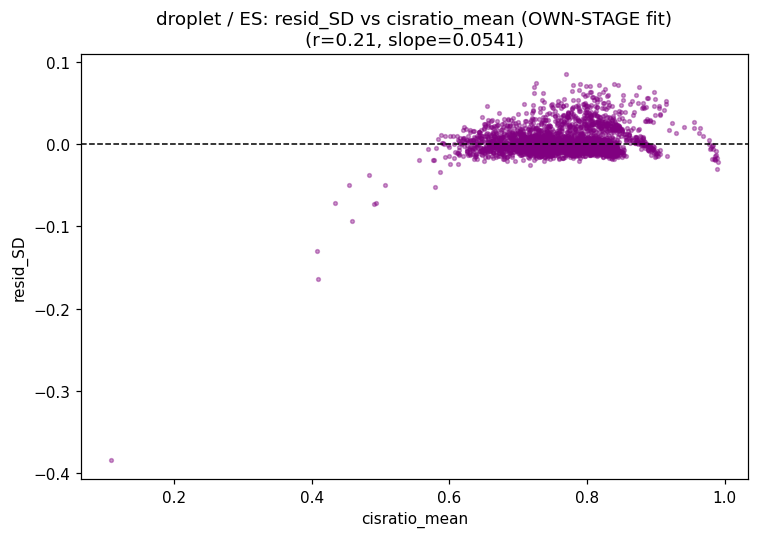

  [droplet / ES] resid_SD vs mean: r=0.212, slope=0.05412


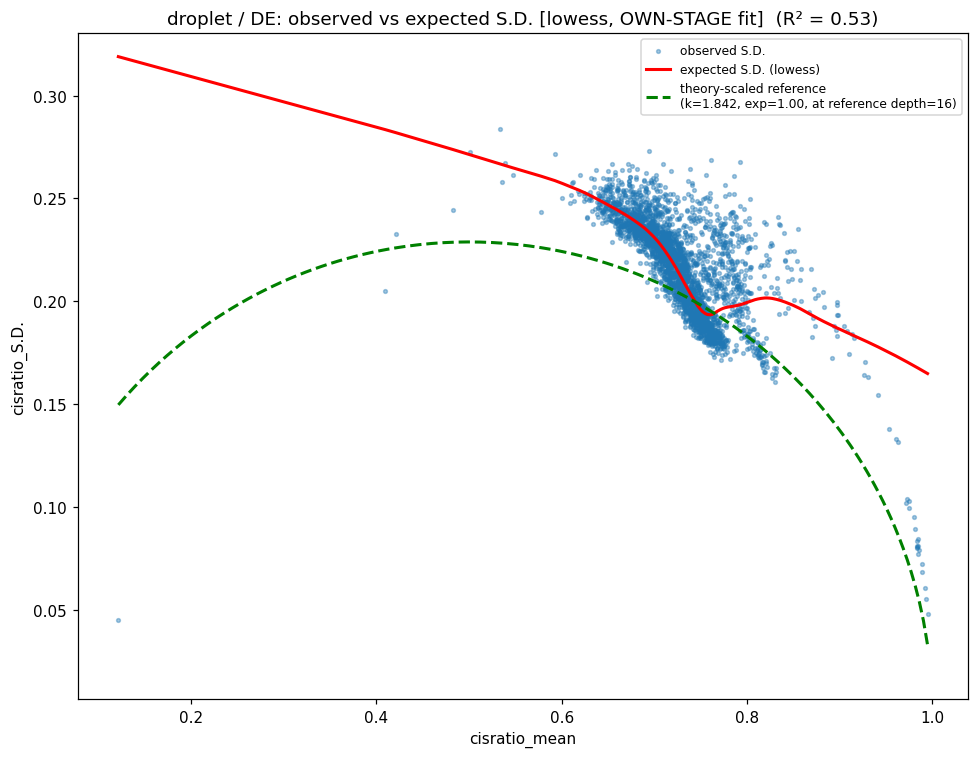

  [droplet / DE] method=lowess, R²=0.534
  wrote: normalized_output/droplet_DE_ownfit_diagnostic_plot.pdf


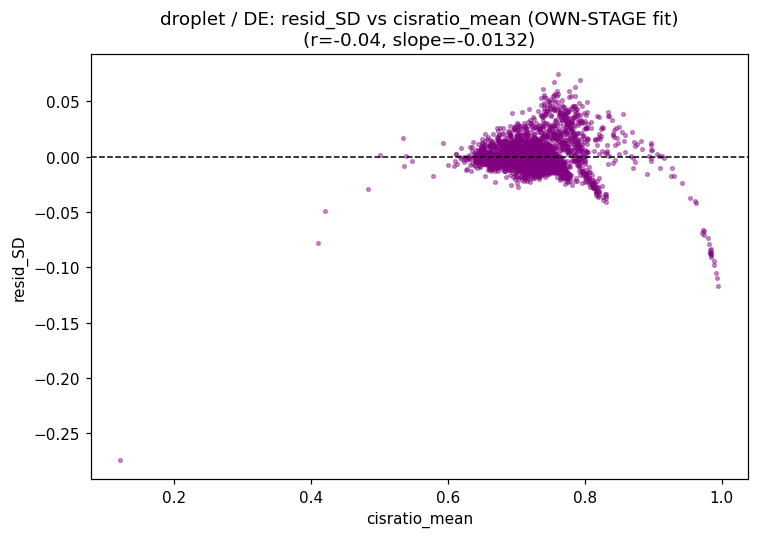

  [droplet / DE] resid_SD vs mean: r=-0.040, slope=-0.01317


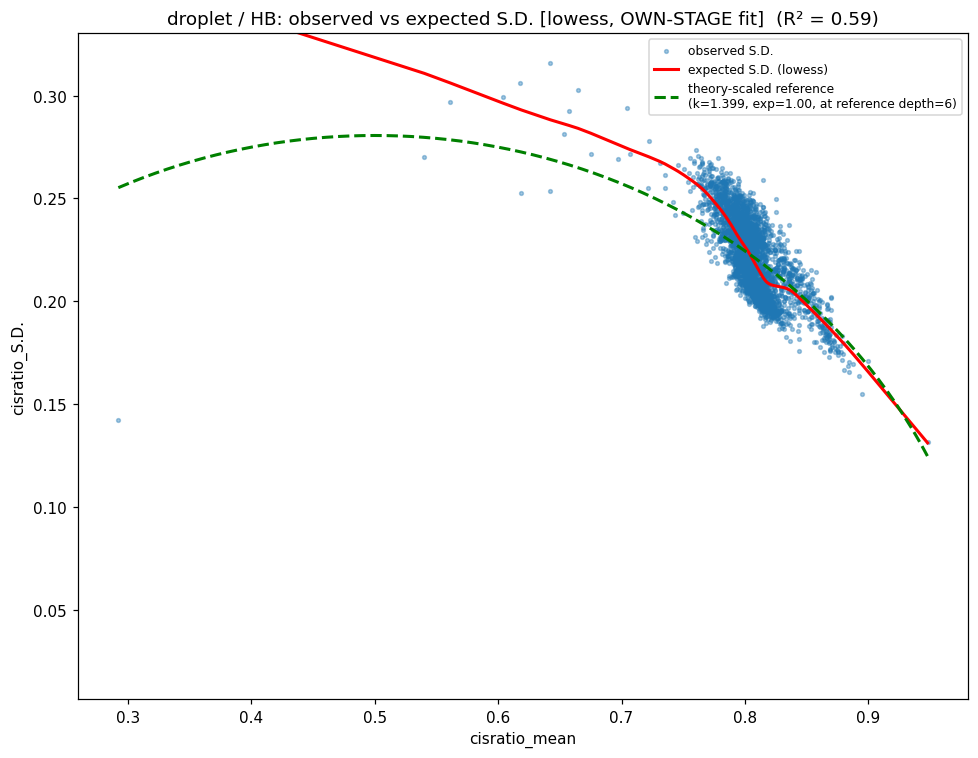

  [droplet / HB] method=lowess, R²=0.586
  wrote: normalized_output/droplet_HB_ownfit_diagnostic_plot.pdf


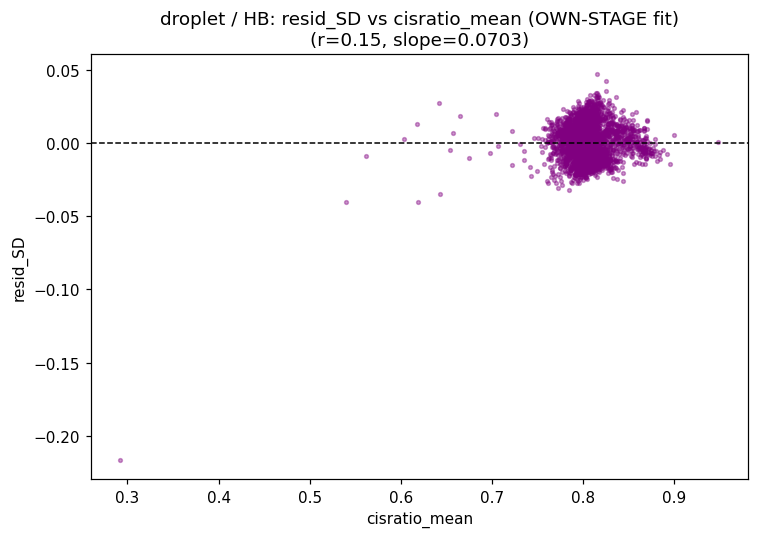

  [droplet / HB] resid_SD vs mean: r=0.146, slope=0.07030


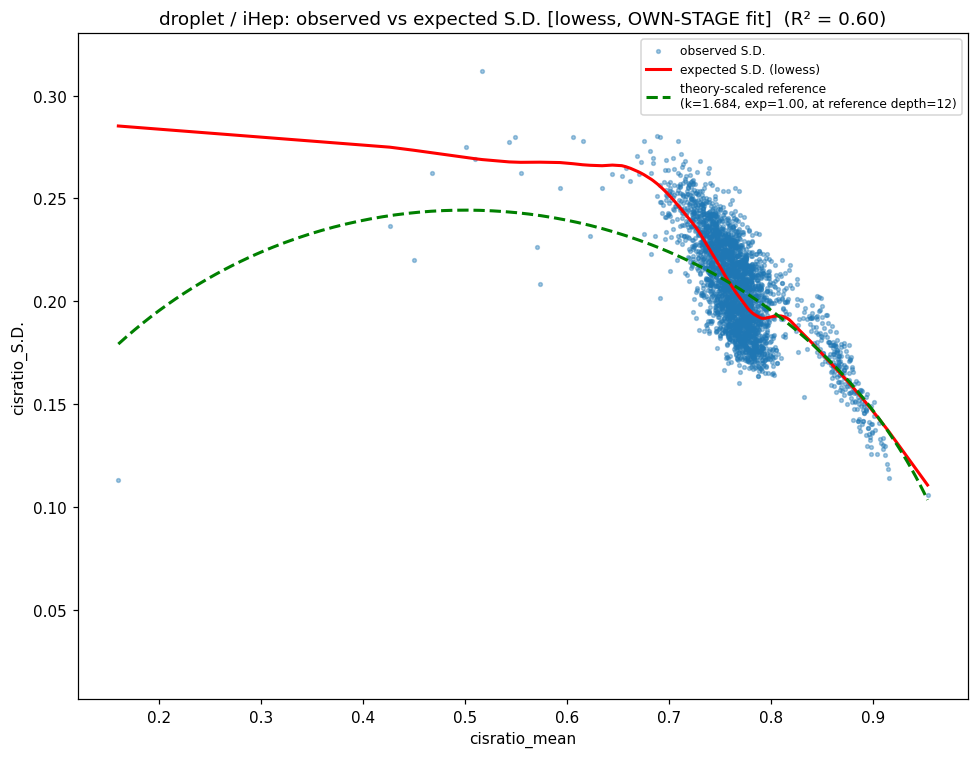

  [droplet / iHep] method=lowess, R²=0.604
  wrote: normalized_output/droplet_iHep_ownfit_diagnostic_plot.pdf


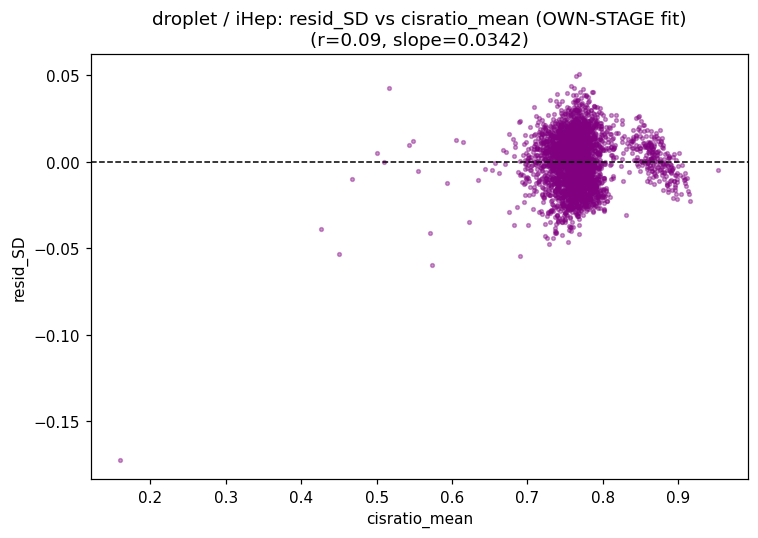

  [droplet / iHep] resid_SD vs mean: r=0.092, slope=0.03420


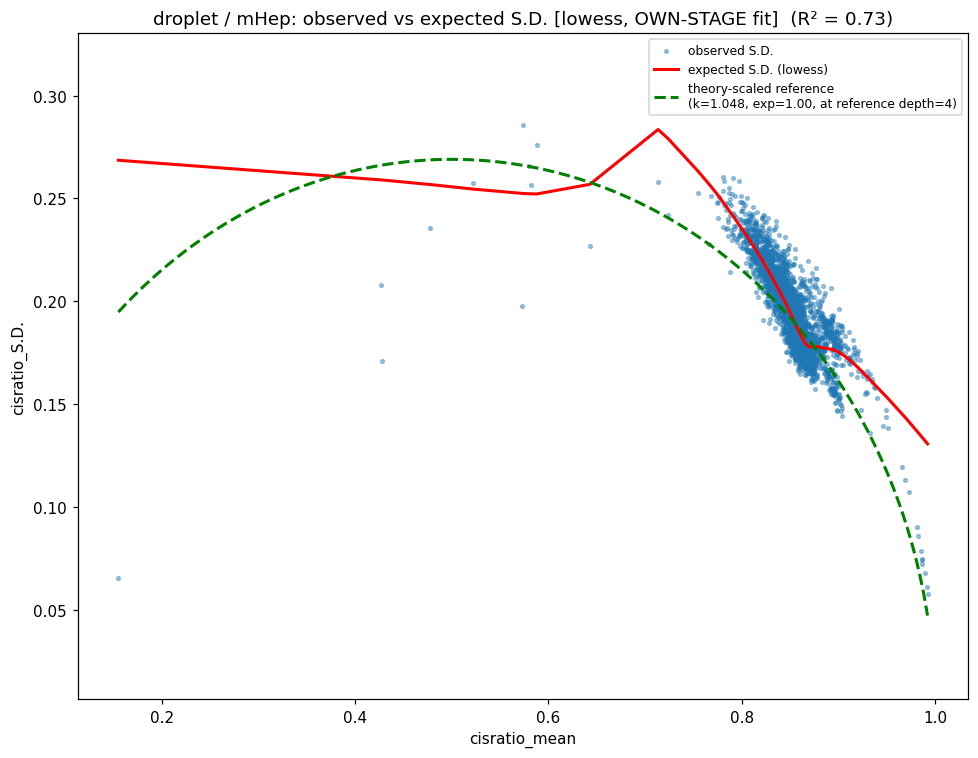

  [droplet / mHep] method=lowess, R²=0.729
  wrote: normalized_output/droplet_mHep_ownfit_diagnostic_plot.pdf


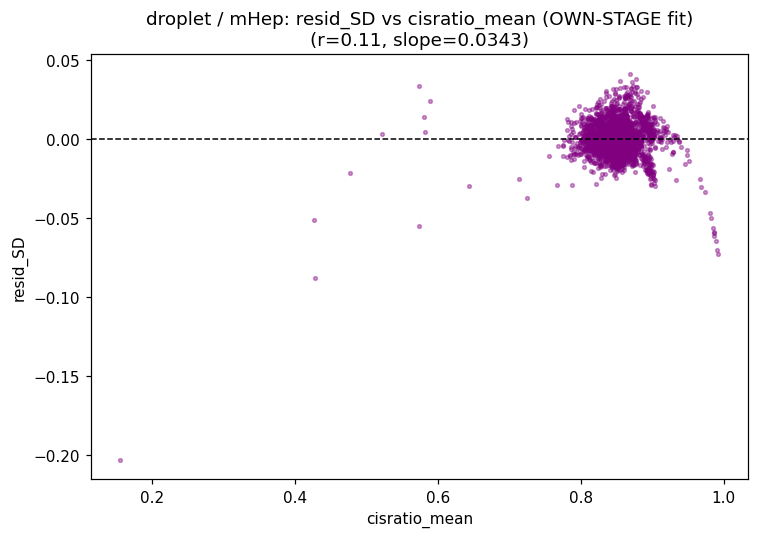

  [droplet / mHep] resid_SD vs mean: r=0.107, slope=0.03430


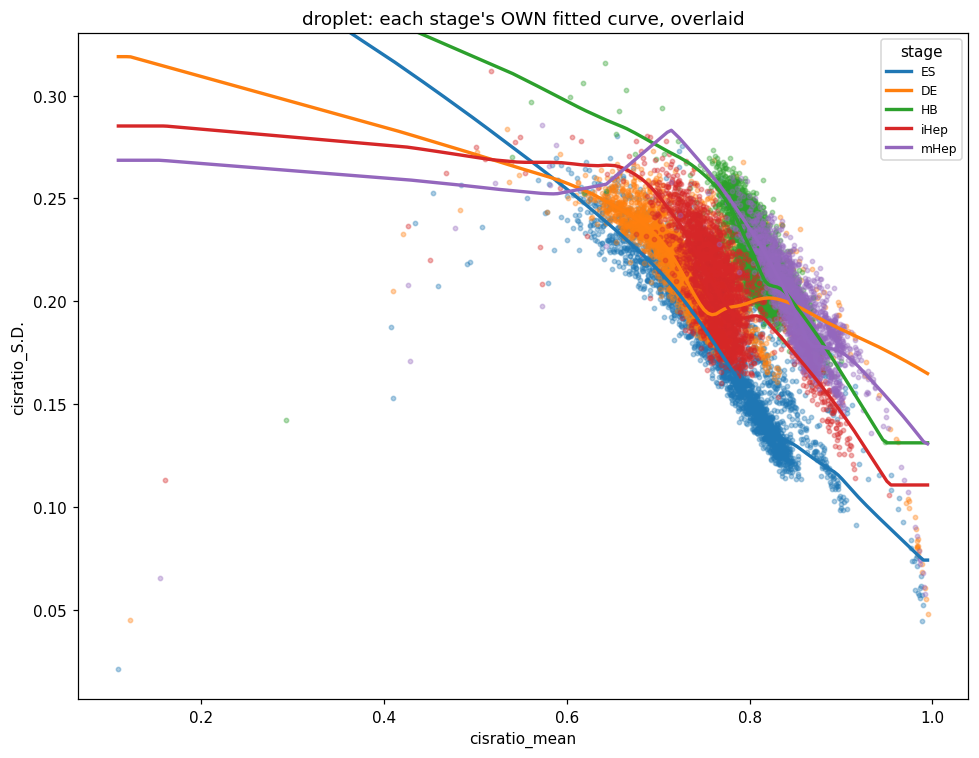

wrote: normalized_output/droplet_own_fits_overlay.pdf

[droplet] R² by stage: {'ES': 0.781, 'DE': 0.534, 'HB': 0.586, 'iHep': 0.604, 'mHep': 0.729}

REMINDER: with per-stage fitting, resid_SD/resid_SD_z compare each bin to OTHER BINS IN THE SAME STAGE only. A stage-to-stage trend in resid_SD now reflects leftover variability not explained by that stage's own mean-S.D. relationship -- a different quantity than the pooled-fit version's resid_SD. Consider which one matches your actual question before comparing results between the two scripts.


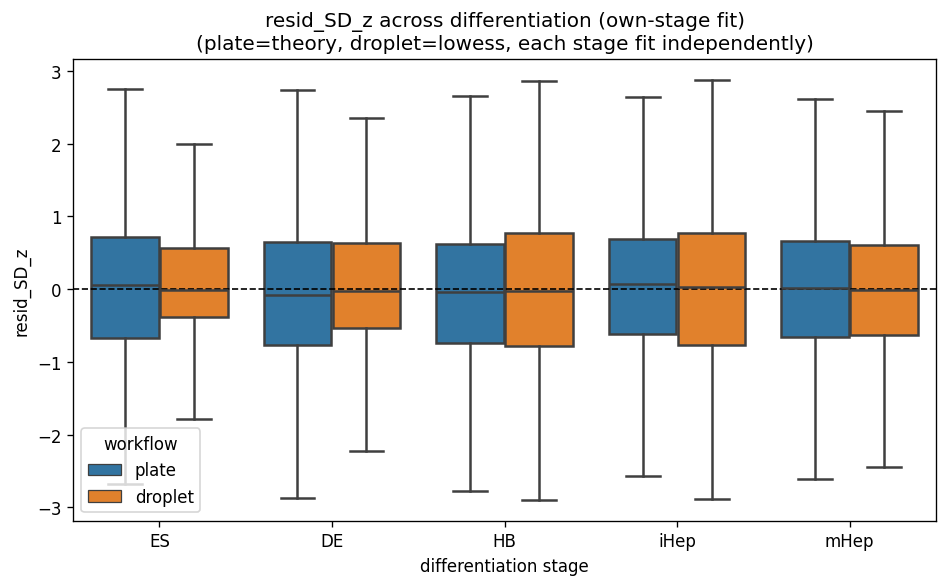

wrote: normalized_output/resid_SD_z_across_stages_ownfit.pdf


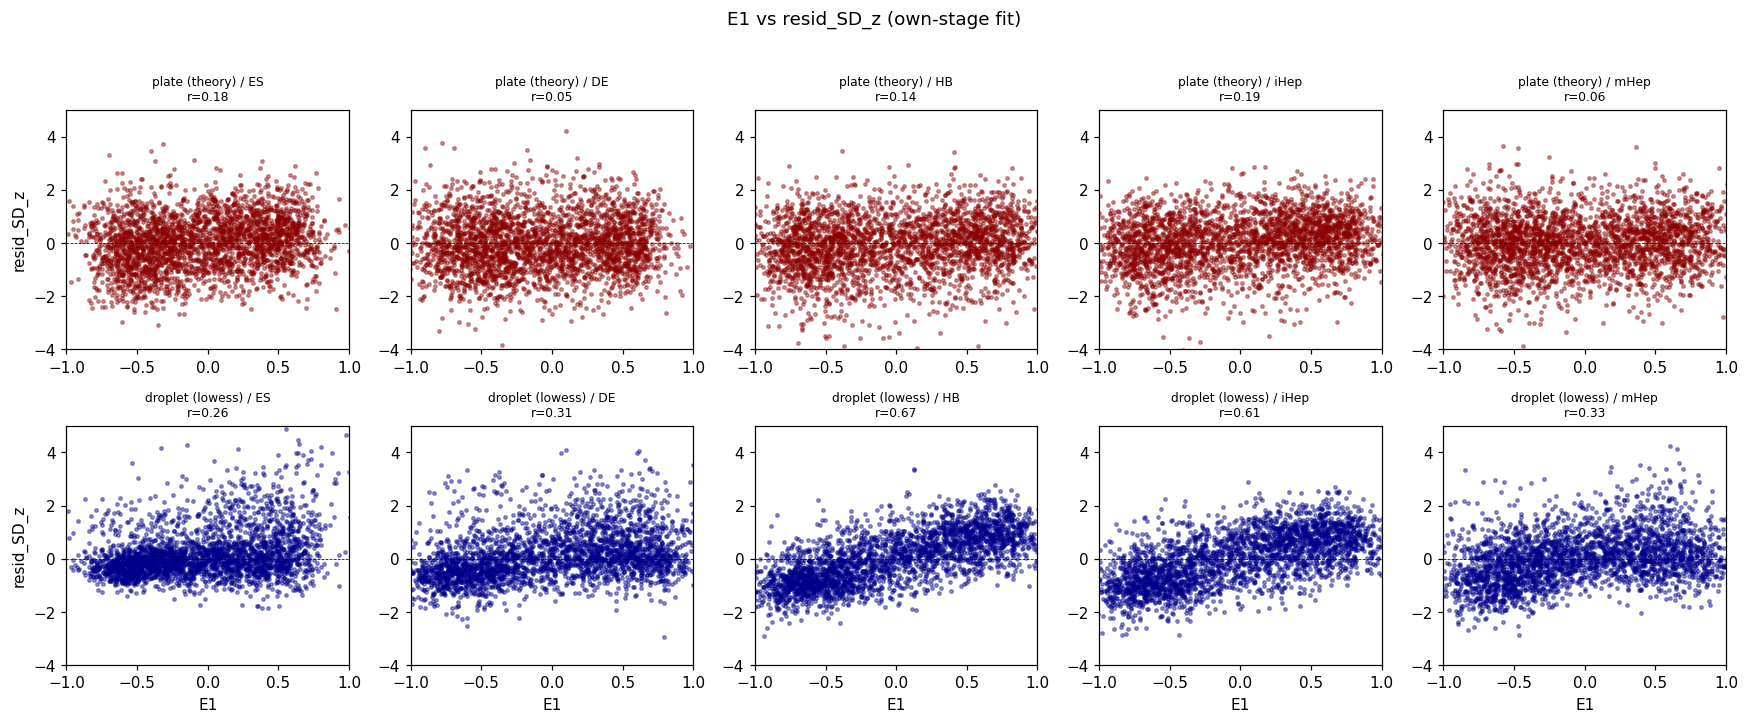

wrote: normalized_output/E1_vs_resid_SD_z_ownfit.pdf

Done. Table: all_stages_all_workflows_normalized_OWNFIT.txt
plate normalized via: theory (fit independently per stage)
droplet normalized via: lowess (fit independently per stage)


In [2]:
"""
normalize_sd_per_stage_fit.py
================================

Same overall pipeline and method choice as normalize_sd_mixed_methods.py
(plate -> theory-scaled binomial model, droplet -> LOWESS), but each STAGE now
fits its OWN expected-S.D. curve independently, instead of pooling all 5
stages into one shared per-workflow curve.

Why you might want this instead of the pooled version:
  - The pooled version ASSUMES one baseline (one k, or one LOWESS curve)
    applies equally well to every differentiation stage. This version tests
    that assumption: if each stage's own fit looks similar to the others
    (similar k, similar curve shape), that supports using the simpler pooled
    baseline. If stages diverge noticeably, that's itself an interesting
    finding (e.g. overdispersion k changing across differentiation) that the
    pooled version would have hidden/averaged away.
  - The trade-off: each stage now has less data to fit on than the pooled
    version, so per-stage fits (especially LOWESS) will be noisier -- keep
    this in mind if a stage has few bins.

resid_SD here is computed against EACH BIN'S OWN STAGE'S curve, so a bin's
residual reflects "how variable is this bin relative to other bins in the
SAME stage" -- not relative to the whole differentiation time course. This
changes what a stage-to-stage trend in resid_SD actually means: with the
pooled version, a shift across stages could reflect either (a) genuine change
in variability, or (b) genuine change in the mean distribution combined with
a fixed pooled curve. With per-stage fits, each stage's residual is already
"corrected" for its own mean-S.D. relationship, so a stage-to-stage trend in
resid_SD reflects something closer to "the typical LEFTOVER variability not
explained by within-stage mean," which is a subtly different question --
worth thinking about which one matches what you actually want to report.

pip install pandas numpy statsmodels matplotlib seaborn scipy --break-system-packages
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ---------------- config (same as normalize_sd_mixed_methods.py) --------------

STAGES = ["ES", "DE", "HB", "iHep", "mHep"]
contact_dist = 300

PLATE_STAGE_TOKEN = {stage: stage for stage in STAGES}
DROPLET_STAGE_TOKEN = {stage: stage for stage in STAGES}
DROPLET_STAGE_TOKEN["ES"] = "H1"

PLATE_PATHS = {
    stage: f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/'
           f'comp_bin_cisratio_{PLATE_STAGE_TOKEN[stage]}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'
    for stage in STAGES
}
DROPLET_PATHS = {
    stage: f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/'
           f'dropletHiC_{DROPLET_STAGE_TOKEN[stage]}_comp_bin_cisratio_filter<0.3kb.txt'
    for stage in STAGES
}

COL_MEAN = "cisratio_mean"
COL_SD   = "cisratio_S.D."
COL_N    = "total_counts_Mean"
COL_SUM  = "total_counts_sum"

MIN_TOTAL_COUNTS = {"plate": 500, "droplet": 1000}

METHOD_BY_WORKFLOW = {
    "plate": "theory",
    "droplet": "lowess",
}

FIX_EXPONENT_AT_ONE = True
LOWESS_FRAC = 0.4
LOWESS_ROBUST_ITERS = 3
MIN_ROWS_FOR_LOWESS = 30
N_MEAN_BINS_FOR_LOCAL_SPREAD = 20

OUTDIR = Path("normalized_output")
OUTDIR.mkdir(exist_ok=True)

# ---------------- fitting methods (identical to mixed-methods script) ---------


def fit_theory_scaled(mean_vals, sd_vals, n_vals, fix_exponent_at_one=FIX_EXPONENT_AT_ONE):
    p = np.clip(mean_vals, 1e-6, 1 - 1e-6)
    n = np.where(n_vals > 0, n_vals, np.nan)
    theory = np.sqrt(p * (1 - p) / n)
    valid = (~np.isnan(theory)) & (~np.isnan(sd_vals)) & (theory > 0) & (sd_vals > 0)

    if fix_exponent_at_one:
        k = np.sum(sd_vals[valid] * theory[valid]) / np.sum(theory[valid] ** 2)
        exponent = 1.0
    else:
        x = np.log(theory[valid]); y = np.log(sd_vals[valid])
        exponent, log_k = np.polyfit(x, y, deg=1)
        k = np.exp(log_k)

    def predict_fn(mean_arr, n_arr):
        m = np.clip(np.asarray(mean_arr, dtype=float), 1e-6, 1 - 1e-6)
        nn = np.where(np.asarray(n_arr, dtype=float) > 0, n_arr, np.nan)
        th = np.sqrt(m * (1 - m) / nn)
        return k * (th ** exponent)

    return predict_fn, {"method": "theory", "k": k, "exponent": exponent}


def fit_lowess(mean_vals, sd_vals, n_vals=None, frac=LOWESS_FRAC):
    n_valid = np.sum(~np.isnan(mean_vals) & ~np.isnan(sd_vals))

    if n_valid >= MIN_ROWS_FOR_LOWESS:
        from statsmodels.nonparametric.smoothers_lowess import lowess
        mask = ~np.isnan(mean_vals) & ~np.isnan(sd_vals)
        x, y = mean_vals[mask], sd_vals[mask]
        order = np.argsort(x)
        smoothed = lowess(y[order], x[order], frac=frac, it=LOWESS_ROBUST_ITERS, return_sorted=True)
        xs, ys = smoothed[:, 0], smoothed[:, 1]
        xs_u, idx = np.unique(xs, return_index=True)
        ys_u = ys[idx]

        def predict_fn(mean_arr, n_arr=None):
            m = np.asarray(mean_arr, dtype=float)
            out = np.full(m.shape, np.nan)
            valid = ~np.isnan(m)
            out[valid] = np.interp(m[valid], xs_u, ys_u, left=ys_u[0], right=ys_u[-1])
            return out

        return predict_fn, {"method": "lowess", "frac": frac}
    else:
        mask = ~np.isnan(mean_vals) & ~np.isnan(sd_vals)
        coeffs = np.polyfit(mean_vals[mask], sd_vals[mask], deg=2)

        def predict_fn(mean_arr, n_arr=None):
            return np.polyval(coeffs, np.asarray(mean_arr, dtype=float))

        return predict_fn, {"method": "quadratic_fallback"}


def fit_for_workflow(workflow, mean_vals, sd_vals, n_vals):
    method = METHOD_BY_WORKFLOW.get(workflow, "lowess")
    if method == "theory":
        return fit_theory_scaled(mean_vals, sd_vals, n_vals)
    else:
        return fit_lowess(mean_vals, sd_vals, n_vals)


def compute_r2(sd_vals, expected):
    valid = ~np.isnan(sd_vals) & ~np.isnan(expected)
    ss_res = np.nansum((sd_vals[valid] - expected[valid]) ** 2)
    ss_tot = np.nansum((sd_vals[valid] - np.nanmean(sd_vals[valid])) ** 2)
    return 1 - ss_res / ss_tot if ss_tot > 0 else np.nan


def local_residual_spread(mean_vals, resid_vals, n_bins=N_MEAN_BINS_FOR_LOCAL_SPREAD):
    mask = ~np.isnan(mean_vals) & ~np.isnan(resid_vals)
    x, r = mean_vals[mask], resid_vals[mask]
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 3:
        g = np.nanstd(r) if np.nanstd(r) > 0 else 1.0
        return lambda m: np.full(np.asarray(m).shape, g)

    bin_idx = np.digitize(x, edges[1:-1])
    centers, stds = [], []
    for b in range(len(edges) - 1):
        sel = bin_idx == b
        if sel.sum() >= 5:
            centers.append(x[sel].mean()); stds.append(r[sel].std(ddof=1))
    if len(centers) < 2:
        g = np.nanstd(r) if np.nanstd(r) > 0 else 1.0
        return lambda m: np.full(np.asarray(m).shape, g)

    centers, stds = np.array(centers), np.array(stds)
    order = np.argsort(centers); centers, stds = centers[order], stds[order]

    def predict_std(m):
        m = np.asarray(m, dtype=float)
        out = np.full(m.shape, np.nan)
        valid = ~np.isnan(m)
        out[valid] = np.interp(m[valid], centers, stds, left=stds[0], right=stds[-1])
        out[out <= 0] = np.nanmedian(stds[stds > 0]) if np.any(stds > 0) else 1.0
        return out

    return predict_std


def apply_normalization(df, predict_fn, local_std_fn):
    mean_vals = df[COL_MEAN].to_numpy(dtype=float)
    sd_vals = df[COL_SD].to_numpy(dtype=float)
    n_vals = df[COL_N].to_numpy(dtype=float) if COL_N in df.columns else np.full(len(df), np.nan)

    df = df.copy()
    df["expected_SD"] = predict_fn(mean_vals, n_vals)
    df["resid_SD"] = sd_vals - df["expected_SD"]
    df["resid_SD_local_std"] = local_std_fn(mean_vals)
    df["resid_SD_z"] = df["resid_SD"] / df["resid_SD_local_std"]
    return df


# ---------------- load -------------------------------------------------------

def load_all():
    data = {"plate": {}, "droplet": {}}
    for stage, path in PLATE_PATHS.items():
        if not Path(path).exists():
            print(f"[skip] plate {stage}: file not found at {path}")
            continue
        df = pd.read_csv(path, sep="\t", index_col=0).reset_index()
        df["stage"] = stage; df["workflow"] = "plate"
        df = df[df[COL_SUM] >= MIN_TOTAL_COUNTS["plate"]]
        data["plate"][stage] = df

    for stage, path in DROPLET_PATHS.items():
        if not Path(path).exists():
            print(f"[skip] droplet {stage}: file not found at {path}")
            continue
        df = pd.read_csv(path, sep="\t", index_col=0).reset_index()
        df["stage"] = stage; df["workflow"] = "droplet"
        df = df[df[COL_SUM] >= MIN_TOTAL_COUNTS["droplet"]]
        data["droplet"][stage] = df

    return data


# ---------------- diagnostics -------------------------------------------------

def compute_workflow_ylim(stage_dfs, pad_frac=0.05):
    all_sd = pd.concat([df[COL_SD] for df in stage_dfs.values()], ignore_index=True).to_numpy(dtype=float)
    valid = all_sd[~np.isnan(all_sd)]
    if valid.size == 0:
        return None
    lo, hi = np.nanmin(valid), np.nanmax(valid)
    pad = (hi - lo) * pad_frac
    return (lo - pad, hi + pad)


def plot_diagnostic(label, mean_vals, sd_vals, n_vals, predict_fn, fit_meta, out_name, ylim=None,
                     theory_overlay=None, reference_n=None, x_range=None):
    order = np.argsort(mean_vals)
    expected = predict_fn(mean_vals, n_vals)
    r2 = compute_r2(sd_vals, expected)

    fig, ax = plt.subplots(figsize=(9, 7), dpi=110)
    ax.scatter(mean_vals, sd_vals, s=6, alpha=0.4, label="observed S.D.")

    curve_n = reference_n if reference_n is not None else np.nanmedian(n_vals)
    if x_range is not None:
        x_lo, x_hi = x_range
    else:
        x_lo, x_hi = np.nanmin(mean_vals), np.nanmax(mean_vals)

    if fit_meta["method"] == "theory":
        x_grid = np.linspace(x_lo, x_hi, 200)
        curve = predict_fn(x_grid, np.full_like(x_grid, curve_n))
        ax.plot(x_grid, curve, color="red", lw=2,
                label=f"theory-scaled expected S.D.\n(k={fit_meta['k']:.3f}, "
                      f"exp={fit_meta['exponent']:.2f}, at reference depth={curve_n:.0f})")
    else:
        ax.plot(mean_vals[order], expected[order], color="red", lw=2,
                label=f"expected S.D. ({fit_meta['method']})")

    if theory_overlay is not None and fit_meta["method"] != "theory":
        predict_theory_fn, theory_meta = theory_overlay
        x_grid = np.linspace(x_lo, x_hi, 200)
        theory_curve = predict_theory_fn(x_grid, np.full_like(x_grid, curve_n))
        ax.plot(x_grid, theory_curve, color="green", lw=2, ls="--",
                label=f"theory-scaled reference\n(k={theory_meta['k']:.3f}, "
                      f"exp={theory_meta['exponent']:.2f}, at reference depth={curve_n:.0f})")

    ax.set_xlabel("cisratio_mean"); ax.set_ylabel("cisratio_S.D.")
    ax.set_title(f"{label}: observed vs expected S.D. [{fit_meta['method']}, OWN-STAGE fit]  "
                 f"(R\u00b2 = {r2:.2f})")
    ax.legend(fontsize=8)
    if ylim is not None:
        ax.set_ylim(*ylim)
    fig.tight_layout()

    out_path = OUTDIR / f"{out_name}_diagnostic_plot.pdf"
    fig.savefig(out_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"  [{label}] method={fit_meta['method']}, R\u00b2={r2:.3f}")
    if fit_meta["method"] == "theory":
        print(f"    k={fit_meta['k']:.4f}, exponent={fit_meta['exponent']:.3f}")
    print(f"  wrote: {out_path}")
    return r2


def plot_diagnostic_by_stage_own_fits(workflow, stage_fits, out_name, ylim=None):
    """Overlay every stage's own scatter AND own fitted curve (matching colors) on one figure,
    so you can directly compare how much the fitted relationship itself shifts across stages."""
    fig, ax = plt.subplots(figsize=(9, 7), dpi=110)
    palette = sns.color_palette("tab10", n_colors=len(STAGES))
    stage_colors = dict(zip(STAGES, palette))

    all_mean = np.concatenate([sf["mean_vals"] for sf in stage_fits.values()])
    x_lo, x_hi = np.nanmin(all_mean), np.nanmax(all_mean)
    x_grid = np.linspace(x_lo, x_hi, 200)

    for stage, sf in stage_fits.items():
        color = stage_colors[stage]
        ax.scatter(sf["mean_vals"], sf["sd_vals"], s=8, alpha=0.35, color=color)

        if sf["fit_meta"]["method"] == "theory":
            ref_n = np.nanmedian(sf["n_vals"])
            curve = sf["predict_fn"](x_grid, np.full_like(x_grid, ref_n))
            label = f"{stage} (k={sf['fit_meta']['k']:.2f})"
        else:
            order = np.argsort(sf["mean_vals"])
            # re-evaluate on the shared x_grid for visual comparability
            curve = sf["predict_fn"](x_grid, None)
            label = f"{stage}"

        ax.plot(x_grid, curve, color=color, lw=2.2, label=label)

    ax.set_xlabel("cisratio_mean"); ax.set_ylabel("cisratio_S.D.")
    ax.set_title(f"{workflow}: each stage's OWN fitted curve, overlaid")
    ax.legend(fontsize=8, title="stage")
    if ylim is not None:
        ax.set_ylim(*ylim)
    fig.tight_layout()

    out_path = OUTDIR / f"{out_name}_own_fits_overlay.pdf"
    fig.savefig(out_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"wrote: {out_path}")


def plot_residual_vs_mean(label, mean_vals, resid_vals, out_name, ylim=None):
    fig, ax = plt.subplots(figsize=(7, 5), dpi=110)
    ax.scatter(mean_vals, resid_vals, s=6, alpha=0.4, color="purple")
    ax.axhline(0, color="black", lw=1, ls="--")

    valid = ~np.isnan(mean_vals) & ~np.isnan(resid_vals)
    if valid.sum() >= 2:
        from scipy.stats import pearsonr
        r, _ = pearsonr(mean_vals[valid], resid_vals[valid])
        slope = np.polyfit(mean_vals[valid], resid_vals[valid], deg=1)[0]
    else:
        r, slope = np.nan, np.nan

    ax.set_xlabel("cisratio_mean"); ax.set_ylabel("resid_SD")
    ax.set_title(f"{label}: resid_SD vs cisratio_mean (OWN-STAGE fit)\n"
                 f"(r={r:.2f}, slope={slope:.4f})")
    if ylim is not None:
        ax.set_ylim(*ylim)
    fig.tight_layout()

    out_path = OUTDIR / f"{out_name}_resid_vs_mean.pdf"
    fig.savefig(out_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"  [{label}] resid_SD vs mean: r={r:.3f}, slope={slope:.5f}")
    return r, slope


# ---------------- fit EACH STAGE INDEPENDENTLY ---------------------------------

def fit_and_normalize_per_stage(data):
    """KEY DIFFERENCE from the mixed-methods (pooled) script: fit_for_workflow() is called
    separately for EACH STAGE, using only that stage's own data -- no pooling across stages."""
    normalized = {"plate": {}, "droplet": {}}
    k_by_stage = {"plate": {}, "droplet": {}}
    r2_by_stage = {"plate": {}, "droplet": {}}

    for workflow in ["plate", "droplet"]:
        stage_dfs = data[workflow]
        if not stage_dfs:
            continue

        workflow_ylim = compute_workflow_ylim(stage_dfs)
        stage_fits = {}  # for the overlay plot

        for stage, df in stage_dfs.items():
            mean_vals = df[COL_MEAN].to_numpy(dtype=float)
            sd_vals = df[COL_SD].to_numpy(dtype=float)
            n_vals = df[COL_N].to_numpy(dtype=float) if COL_N in df.columns else np.full(len(df), np.nan)

            # fit USING ONLY THIS STAGE'S OWN DATA
            predict_fn, fit_meta = fit_for_workflow(workflow, mean_vals, sd_vals, n_vals)

            predict_theory_fn, theory_meta = fit_theory_scaled(mean_vals, sd_vals, n_vals)
            theory_overlay = (predict_theory_fn, theory_meta)

            expected = predict_fn(mean_vals, n_vals)
            resid = sd_vals - expected
            local_std_fn = local_residual_spread(mean_vals, resid)

            r2 = plot_diagnostic(
                f"{workflow} / {stage}", mean_vals, sd_vals, n_vals, predict_fn, fit_meta,
                out_name=f"{workflow}_{stage}_ownfit",
                ylim=workflow_ylim,
                theory_overlay=theory_overlay if fit_meta["method"] != "theory" else None,
            )
            plot_residual_vs_mean(f"{workflow} / {stage}", mean_vals, resid,
                                   out_name=f"{workflow}_{stage}_ownfit")

            r2_by_stage[workflow][stage] = r2
            if fit_meta["method"] == "theory":
                k_by_stage[workflow][stage] = fit_meta["k"]

            stage_fits[stage] = {
                "mean_vals": mean_vals, "sd_vals": sd_vals, "n_vals": n_vals,
                "predict_fn": predict_fn, "fit_meta": fit_meta,
            }

            normalized[workflow][stage] = apply_normalization(df, predict_fn, local_std_fn)

        plot_diagnostic_by_stage_own_fits(workflow, stage_fits, out_name=f"{workflow}",
                                           ylim=workflow_ylim)

        print(f"\n[{workflow}] R\u00b2 by stage: "
              f"{ {s: round(v, 3) for s, v in r2_by_stage[workflow].items()} }")
        if k_by_stage[workflow]:
            print(f"[{workflow}] overdispersion k by stage: "
                  f"{ {s: round(v, 4) for s, v in k_by_stage[workflow].items()} }")
            print(f"  -> if k changes meaningfully across stages, that's evidence excess "
                  f"variability (beyond binomial sampling) itself shifts during differentiation, "
                  f"not just the mean cisratio distribution.")

    print("\nREMINDER: with per-stage fitting, resid_SD/resid_SD_z compare each bin to OTHER BINS "
          "IN THE SAME STAGE only. A stage-to-stage trend in resid_SD now reflects leftover "
          "variability not explained by that stage's own mean-S.D. relationship -- a different "
          "quantity than the pooled-fit version's resid_SD. Consider which one matches your "
          "actual question before comparing results between the two scripts.")

    return normalized, r2_by_stage, k_by_stage


# ---------------- assemble + plot trend across stages --------------------------

def assemble_long(normalized):
    frames = []
    for workflow in ["plate", "droplet"]:
        for stage, df in normalized[workflow].items():
            frames.append(df)
    return pd.concat(frames, ignore_index=True)


def plot_stage_trend(long_df, value_col="resid_SD_z", title_suffix="(own-stage fit)"):
    fig, ax = plt.subplots(figsize=(8, 5), dpi=120)
    sns.boxplot(data=long_df, x="stage", y=value_col, hue="workflow", order=STAGES,
                showfliers=False, ax=ax)
    ax.axhline(0, color="black", lw=1, ls="--")
    ax.set_title(f"{value_col} across differentiation {title_suffix}\n"
                 f"(plate={METHOD_BY_WORKFLOW['plate']}, droplet={METHOD_BY_WORKFLOW['droplet']}, "
                 f"each stage fit independently)")
    ax.set_xlabel("differentiation stage"); ax.set_ylabel(value_col)
    fig.tight_layout()
    out_path = OUTDIR / f"{value_col}_across_stages_ownfit.pdf"
    fig.savefig(out_path)
    plt.show()
    plt.close(fig)
    print(f"wrote: {out_path}")


def plot_e1_vs_resid(long_df, e1_col="E1", value_col="resid_SD_z", title_suffix="(own-stage fit)"):
    from scipy.stats import pearsonr

    workflows = [wf for wf in ["plate", "droplet"] if wf in long_df["workflow"].unique()]
    stages_present = [s for s in STAGES if s in long_df["stage"].unique()]

    fig, axes = plt.subplots(len(workflows), len(stages_present),
                              figsize=(3.2 * len(stages_present), 3.2 * len(workflows)),
                              dpi=110, squeeze=False)

    for i, workflow in enumerate(workflows):
        for j, stage in enumerate(stages_present):
            ax = axes[i][j]
            sub = long_df[(long_df["workflow"] == workflow) & (long_df["stage"] == stage)]
            x = sub[e1_col]; y = sub[value_col]
            mask = (~x.isna()) & (~y.isna()) & np.isfinite(x) & np.isfinite(y)
            r = pearsonr(x[mask], y[mask])[0] if mask.sum() >= 2 else np.nan

            ax.scatter(x, y, s=5, alpha=0.4, color="darkblue" if workflow == "droplet" else "darkred")
            ax.axhline(0, color="black", lw=0.5, ls="--")
            ax.set_xlim(-1, 1)
            ax.set_ylim(-4, 5)
            ax.set_title(f"{workflow} ({METHOD_BY_WORKFLOW[workflow]}) / {stage}\nr={r:.2f}", fontsize=8)
            if i == len(workflows) - 1:
                ax.set_xlabel(e1_col)
            if j == 0:
                ax.set_ylabel(value_col)

    fig.suptitle(f"{e1_col} vs {value_col} {title_suffix}", y=1.02)
    fig.tight_layout()
    out_path = OUTDIR / f"{e1_col}_vs_{value_col}_ownfit.pdf"
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"wrote: {out_path}")


# ---------------- run --------------------------------------------------------

if __name__ == "__main__":
    data = load_all()

    normalized, r2_by_stage, k_by_stage = fit_and_normalize_per_stage(data)
    long_df = assemble_long(normalized)
    long_df.to_csv(OUTDIR / "all_stages_all_workflows_normalized_OWNFIT.txt", sep="\t", index=False)

    plot_stage_trend(long_df, "resid_SD_z")
    if "E1" in long_df.columns:
        plot_e1_vs_resid(long_df, "E1", "resid_SD_z")

    print("\nDone. Table: all_stages_all_workflows_normalized_OWNFIT.txt")
    print(f"plate normalized via: {METHOD_BY_WORKFLOW['plate']} (fit independently per stage)")
    print(f"droplet normalized via: {METHOD_BY_WORKFLOW['droplet']} (fit independently per stage)")